# Project Week 10
## Shahab Esfandiar

-------------------------------------------------------------------------------------------------

### *At first, we should import the required libraries such as Numpy, Tensorflow, Skimage, Matplotlib and so on*

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import math
from osgeo import gdal
import matplotlib.pyplot as plt
import os
import shutil
import matplotlib.patches as mpatches
from skimage import exposure
from skimage.io import imread, imshow,imsave
from tqdm import tqdm_notebook as tqdm
import tensorflow as tf
from tensorflow.python.keras import backend as K
from keras.models import *
from keras.layers import *
from keras.optimizers import *
import pandas as pd
from prettytable import PrettyTable
from keras import callbacks
import time
from tensorflow.keras.utils import to_categorical
from pycocotools import mask
from skimage import measure
from sklearn.model_selection import train_test_split
from decimal import *
from matplotlib.colors import ListedColormap,to_rgb
from matplotlib.patches import Patch
from keras.metrics import MeanIoU
import sklearn
from prettytable import PrettyTable
import simple_colors
import scipy.io
import segmentation_models as sm
import random
from keras.layers import GlobalAveragePooling2D, GlobalMaxPooling2D, Reshape, Dense, multiply, Permute, Concatenate, Conv2D, Add, Activation, Lambda
from keras import backend as K
from keras.activations import sigmoid
from keras import models, layers, regularizers
from keras import backend as K
from keras.regularizers import l2
from datetime import datetime
import cv2
import glob
from matplotlib import pyplot as plt
from patchify import patchify
import tifffile as tiff
from PIL import Image
from sklearn.metrics import accuracy_score, cohen_kappa_score, jaccard_score
from tensorflow import keras
from tensorflow.keras.metrics import MeanIoU
import random

Segmentation Models: using `keras` framework.


-------------------------------------------------------------------------------------------------

### *Then we will draw and display a flowchart of the steps to be performed in this project.*

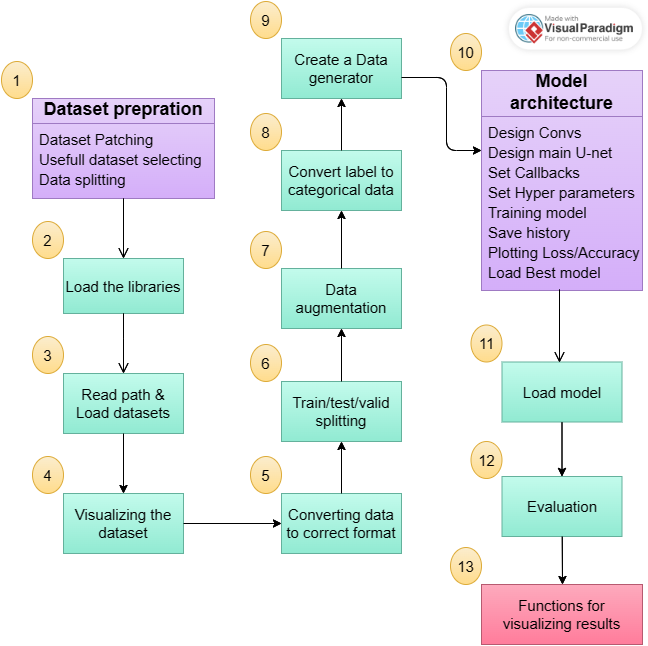

In [106]:
Image("D:\Learning\GeoAi\Week10\Projects\diagram.png")

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">1. Data Prepration</span>

### *First, we use a function to patch our images and masks to have 512 x 512 patches.*

In [29]:
def Patching_img(root_directory,img_dir,patch_size):
    for path, subdirs, files in os.walk(img_dir):
        #pr int(path)  
        dirname = path.split(os.path.sep)[-1]
        #print(dirname)
        images = os.listdir(path)  #List of all image names in this subdirectory
        #print(images)
        for i, image_name in enumerate(images):  
            if image_name.endswith(".tif"):
                #print(image_name)
                image = cv2.imread(path+"/"+image_name, 1)  #Read each image as BGR
                SIZE_X = (image.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (image.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                image = Image.fromarray(image)
                image = image.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #image = image.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                image = np.array(image)             

                #Extract patches from each image
                print("Now patchifying image:", path+"/"+image_name)
                patches_img = patchify(image, (patch_size, patch_size, 3), step=patch_size)  #Step=256 for 256 patches means no overlap
        
                for i in range(patches_img.shape[0]):
                    for j in range(patches_img.shape[1]):
                        
                        single_patch_img = patches_img[i,j,:,:]
                        #single_patch_img = (single_patch_img.astype('float32')) / 255. #We will preprocess using one of the backbones
                        single_patch_img = single_patch_img[0] #Drop the extra unecessary dimension that patchify adds.                               
                        
                        cv2.imwrite(root_directory+"512_patches/images/"+
                                   image_name+"patch_"+str(i)+str(j)+".tif", single_patch_img)
                        #image_dataset.append(single_patch_img)

In [30]:
def Patching_mask(root_directory,mask_dir,patch_size):
    for path, subdirs, files in os.walk(mask_dir):
        #print(path)  
        dirname = path.split(os.path.sep)[-1]

        masks = os.listdir(path)  #List of all image names in this subdirectory
        for i, mask_name in enumerate(masks):  
            if mask_name.endswith(".tif"):           
                mask = cv2.imread(path+"/"+mask_name, 0)  #Read each image as Grey (or color but remember to map each color to an integer)
                SIZE_X = (mask.shape[1]//patch_size)*patch_size #Nearest size divisible by our patch size
                SIZE_Y = (mask.shape[0]//patch_size)*patch_size #Nearest size divisible by our patch size
                mask = Image.fromarray(mask)
                mask = mask.crop((0 ,0, SIZE_X, SIZE_Y))  #Crop from top left corner
                #mask = mask.resize((SIZE_X, SIZE_Y))  #Try not to resize for semantic segmentation
                mask = np.array(mask)             
       
                #Extract patches from each image
                print("Now patchifying mask:", path+"/"+mask_name)
                patches_mask = patchify(mask, (patch_size, patch_size), step=patch_size)  #Step=256 for 256 patches means no overlap
        
                for i in range(patches_mask.shape[0]):
                    for j in range(patches_mask.shape[1]):
                        
                        single_patch_mask = patches_mask[i,j,:,:]
                        #single_patch_img = (single_patch_img.astype('float32')) / 255. #No need to scale masks, but you can do it if you want
                        #single_patch_mask = single_patch_mask[0] #Drop the extra unecessary dimension that patchify adds.                               
                        cv2.imwrite(root_directory+"512_patches/masks/"+
                                   mask_name+"patch_"+str(i)+str(j)+".tif", single_patch_mask)

-------------------------------------------------------------------------------------------------

### *Then we use a function to select the patches that have some data. Because there are patches that have no value and are all 0, which may bias the model and cause problems in its learning process.*

In [31]:
def Realinformation(img_list,msk_list,train_img_dir,train_mask_dir):
    useless=0  #Useless image counter
    for img in range(len(img_list)):   #Using t1_list as all lists are of same size
        img_name=img_list[img]
        mask_name = msk_list[img]
        print("Now preparing image and masks number: ", img)
          
        temp_image=cv2.imread(train_img_dir+img_name, 1)
       
        temp_mask=cv2.imread(train_mask_dir+mask_name, 0)
        #temp_mask=temp_mask.astype(np.uint8)
        
        val, counts = np.unique(temp_mask, return_counts=True)
        
        if (1 - (counts[0]/counts.sum())) > 0.05:  #At least 5% useful area with labels that are not 0
            print("Save Me")
            cv2.imwrite('Datasets/images_with_useful_info/images/'+img_name, temp_image)
            cv2.imwrite('Datasets/images_with_useful_info/masks/'+mask_name, temp_mask)
            
        else:
            print("I am useless")   
            useless +=1

-------------------------------------------------------------------------------------------------

### *Now we select one of the images randomly and display the number of pixels and classes along with the image itself.*


Labels are:  [0 1 4]  and the counts are:  [226951  23833  11360]




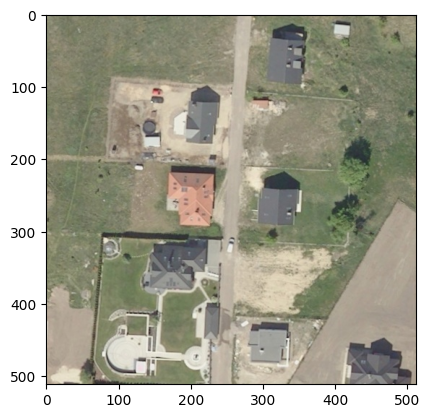

In [38]:
#Change directory
os.chdir("D:\\Learning\\GeoAi\\Week10\\Projects\\Data")

#Quick understanding of the dataset
temp_img = cv2.imread("D:\Learning\GeoAi\Week10\Projects\Data\Test\images\M-34-51-C-d-4-1.tifpatch_01.tif") #3 channels / spectral bands
plt.imshow(temp_img[:,:,[2,1,0]]) #View each channel...
temp_mask = cv2.imread("D:\Learning\GeoAi\Week10\Projects\Data\Test\masks\M-34-51-C-d-4-1.tifpatch_01.tif") #3 channels but all same. 
labels, count = np.unique(temp_mask[:,:,0], return_counts=True) #Check for each channel. All chanels are identical
print("\nLabels are: ", labels, " and the counts are: ", count)
print("\n")

-------------------------------------------------------------------------------------------------

### *Then we have to divide our data into 3 categories: training, testing and validating. For this purpose, we create the desired folders in order and then using the mentioned functions, we first create the patches for our images and masks.*

In [ ]:
#Creat new folder for save patched data in directory
root_directory = 'Train/'

newpath = root_directory+'512_patches/images'
if not os.path.exists(newpath):
    os.makedirs(newpath)

newpath2 = root_directory+'512_patches/masks'
if not os.path.exists(newpath2):
    os.makedirs(newpath2)

In [ ]:
patch_size = 512
img_dir=root_directory+"images/"
mask_dir=root_directory+"masks/"

Patching_img(root_directory,img_dir,patch_size)
Patching_mask(root_directory,mask_dir,patch_size)

train_img_dir = "Test/512_patches/images/"
train_mask_dir = "Test/512_patches/masks/"

img_list = os.listdir(train_img_dir)
msk_list = os.listdir(train_mask_dir)

num_images = len(os.listdir(train_img_dir))
img_num = random.randint(0, num_images-1)


-------------------------------------------------------------------------------------------------

### *Next, we create the relevant folders for our non-zero data and use the real information function to store our final data. We perform these steps 3 times for 3 categories of our dataset.*

In [ ]:
#Creat new folder for save real information in directory
newpath3 = root_directory+'images_with_useful_info/images'
if not os.path.exists(newpath3):
    os.makedirs(newpath3)

newpath4 = root_directory+'images_with_useful_info/masks'
if not os.path.exists(newpath4):
    os.makedirs(newpath4)

Realinformation(img_list,msk_list,train_img_dir,train_mask_dir)

-------------------------------------------------------------------------------------------------

### *At the end of the piece, we write the codes that perform the following steps in order :*

>*1. Access to the files of the said three dataset folders.*

>*2. Separate tif format from filenames.*

>*3. Separate specific names of images in each folder.*

>*4. Selecting the first 10 patches of each main image in the existing folders and transferring them to the images and new masks folders.*

In [68]:
images_dir = "D:\Learning\GeoAi\Week10\Projects\Data\Train\images"
new_images_dir = "D:\\Learning\\GeoAi\\Week10\\Projects\\Train\\images"

masks_dir = "D:\Learning\GeoAi\Week10\Projects\Data\Train\masks"
new_masks_dir = "D:\\Learning\\GeoAi\\Week10\\Projects\\Train\\masks"

num_files = 10
image_files = os.listdir(images_dir)
mask_files = os.listdir(images_dir)

In [69]:
image_names = [f.rsplit(".tif", 1)[0] for f in image_files]
mask_names = [f.rsplit(".tif", 1)[0] for f in mask_files]

unique_images = list(set([n.split(".tifpatch")[0] for n in image_names]))
unique_masks = list(set([n.split(".tifpatch")[0] for n in mask_names]))

In [71]:
for name in unique_images:
    selected_files = [n + ".tif" for n in image_names if n.startswith(name)][:num_files]

    for file in selected_files:
        shutil.copy(os.path.join(images_dir, file), new_images_dir)

for name in unique_masks:
    selected_files = [n + ".tif" for n in mask_names if n.startswith(name)][:num_files]

    for file in selected_files:
        shutil.copy(os.path.join(masks_dir, file), new_masks_dir)

-------------------------------------------------------------------------------------------------

### *With this, we have 10 patches from each image and mask, which makes us sure of the variety and balance of the classes in our data. Finally, we have 400 training patches, 160 validation patches and 10 patches for testing to complete the data preparation section.*

In [3]:
#Set file directory of the location where the data is stored:

train_folder_PATH = "D:\Learning\GeoAi\Week10\Projects\Train"
val_folder_PATH = "D:\Learning\GeoAi\Week10\Projects\Validation"
test_folder_PATH = "D:\Learning\GeoAi\Week10\Projects\Test"

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">2. Data Preprocessing</span>

### *In this section, we first read our data with the following function.*

In [4]:
def readdata(directory, folder_name):

    data_path = os.path.join(directory, folder_name)
    data_list = {}
    for f in tqdm(sorted(os.listdir(data_path))):
        fdir = os.path.join(data_path, f)
        _, ext = os.path.splitext(f)
        if ext.lower() == ".tif":
            imgtype = f[:-4] # Number of characters of the image file. Example, "Image_1.tif" = 11 characters
            image_data=gdal.Open(fdir)
            bands = [image_data.GetRasterBand(i+1).ReadAsArray() for i in range(image_data.RasterCount)]
            data_list[imgtype] = np.stack(bands, axis=2)

    return data_list

In [5]:
#Read data:
train_im_list = readdata(directory=train_folder_PATH, folder_name="images")
train_label_list =readdata(directory=train_folder_PATH, folder_name="masks")

val_im_list = readdata(directory=val_folder_PATH, folder_name="images")
val_label_list =readdata(directory=val_folder_PATH, folder_name="masks")

test_im_list = readdata(directory=test_folder_PATH, folder_name="images")
test_label_list =readdata(directory=test_folder_PATH, folder_name="masks")

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/160 [00:00<?, ?it/s]

  0%|          | 0/160 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

-------------------------------------------------------------------------------------------------

In [6]:
#Check If Everything Works (CIEW)
print("Number of train image & Label: " + str(len(train_im_list)))
print("Number of validation image &  Label: " + str(len(val_im_list)))
print("Number of test image &  Label: " + str(len(test_im_list)))

Number of train image & Label: 400
Number of validation image &  Label: 160
Number of test image &  Label: 10


-------------------------------------------------------------------------------------------------

### *Then, using the following function, we display one of the patches in a classified form along with its mask so that we can see the input data and label visually and have a better understanding of the data type of this project.*

In [7]:
def visualize_ImLa(data,mask):
    f, axarr = plt.subplots(1,2,figsize = (10, 10))
    axarr[0].set_axis_off()
    data = data[:,:,:3]
    axarr[0].imshow(data)
    axarr[0].set_title("Original RGB Image",fontsize=10,color='red')

    a=axarr[1]
    values = np.unique(mask.ravel())
    plt.axis('off')

    colors = ['black' ,'white','green' ,'blue', 'red']
    cmap = ListedColormap(colors)
    legend_labels={'black' :'Background','white':'Building','green':'Woodland', 'blue': 'Water', 'red': 'Road'}

    patches = [Patch(color=color, label=label) for color, label in legend_labels.items()]
    plt.legend(handles=patches,bbox_to_anchor=(1.43,1),facecolor="wheat")
    
    im = axarr[1].imshow(mask,cmap=cmap)
    axarr[1].set_title("Ground Truth Damage Map",fontsize=10,color='red')

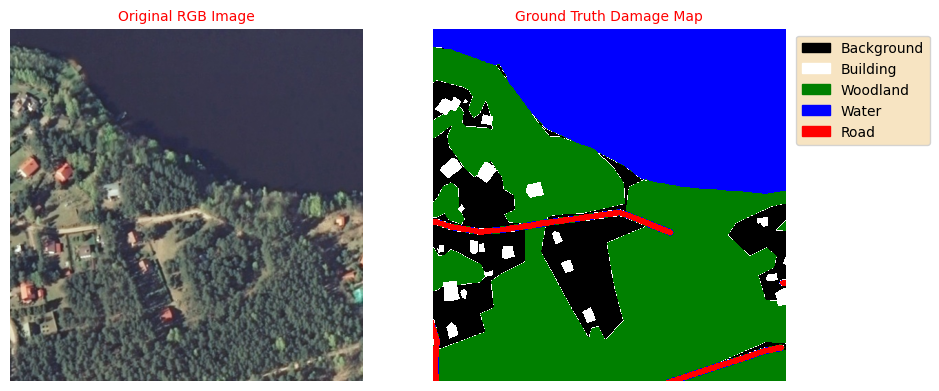

In [20]:
##visualizing  train/val image & label :
img_num = random.choice(list(train_im_list))
visualize_ImLa(train_im_list[img_num], train_label_list[img_num])

-------------------------------------------------------------------------------------------------

### *In the next step, we will create training, testing and validating input data and labels for these datasets.*

In [6]:
# FOR GENERATING TRAINING & Testing Patching:
NoTr = len(train_im_list) #Number of train image as input to patching
NoVa = len(val_im_list) #Number of validation image as input to patching
NBANDS = 3
Patch_size = 512

Xtrain = np.zeros(shape=(0, Patch_size,Patch_size, NBANDS), dtype=np.uint8)
Ytrain = np.zeros(shape=(0, Patch_size,Patch_size, 1), dtype=np.uint8)

Xval = np.zeros(shape=(0, Patch_size,Patch_size, NBANDS), dtype=np.uint8)
Yval = np.zeros(shape=(0, Patch_size,Patch_size, 1), dtype=np.uint8)

Xtest = np.zeros(shape=(0, Patch_size,Patch_size, NBANDS), dtype=np.uint8)
Ytest = np.zeros(shape=(0, Patch_size,Patch_size, 1), dtype=np.uint8)

for S in list(train_im_list) :
    X_toadd = np.expand_dims(train_im_list[S],axis=0)
    Y_toadd = np.expand_dims(train_label_list[S],axis=0)
    Xtrain = np.concatenate((Xtrain, X_toadd), axis=0)
    Ytrain = np.concatenate((Ytrain, Y_toadd), axis=0)

for V in list(val_im_list) :
    X_toadd1 = np.expand_dims(val_im_list[V],axis=0)
    Y_toadd1 = np.expand_dims(val_label_list[V],axis=0)
    Xval = np.concatenate((Xval, X_toadd1), axis=0)
    Yval = np.concatenate((Yval, Y_toadd1), axis=0)

for Z in list(test_im_list) :
    X_toadd2 = np.expand_dims(test_im_list[Z],axis=0)
    Y_toadd2 = np.expand_dims(test_label_list[Z],axis=0)
    Xtest = np.concatenate((Xtest, X_toadd2), axis=0)
    Ytest = np.concatenate((Ytest, Y_toadd2), axis=0)

X_val = Xval 
Y_val = Yval 
X_test = Xtest 
Y_test = Ytest 

print('Shape of Training data', np.shape(Xtrain))
print('Shape of Validation data', np.shape(Xval))
print('Shape of Test data', np.shape(Xtest))

Shape of Training data (400, 512, 512, 3)
Shape of Validation data (160, 512, 512, 3)
Shape of Test data (10, 512, 512, 3)


-------------------------------------------------------------------------------------------------

### *Now we reach the stage of data augmentation and increase the number of training data with methods such as flip and rotation.*

In [7]:
# Data(Train) Augmentation :

#Reverse the order of elements along axis 1 (left/right).
X_train = np.append(Xtrain, [np.fliplr(x) for x in tqdm(Xtrain)], axis=0)
Y_train = np.append(Ytrain, [np.fliplr(x) for x in tqdm(Ytrain)], axis=0)

#Reverse the order of elements along axis 0 (up/down).
X_train = np.append(X_train, [np.flipud(x) for x in tqdm(Xtrain)], axis=0)
Y_train = np.append(Y_train, [np.flipud(x) for x in tqdm(Ytrain)], axis=0)

#Rotate an array by 90 degrees in the plane specified by axes.
X_train = np.append(X_train, [np.rot90(x) for x in tqdm(Xtrain)], axis=0)
Y_train = np.append(Y_train, [np.rot90(x) for x in tqdm(Ytrain)], axis=0)


print("\nNumber of training patches after Augmentation: " + str(len(X_train)))
print("Shape of the image: "+ str(X_train[1].shape))
print("\nNumber of training label  after Augmentation: " + str(len(Y_train)))
print("Shape of the image: "+ str(Y_train[1].shape))

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]


Number of training patches after Augmentation: 1600
Shape of the image: (512, 512, 3)

Number of training label  after Augmentation: 1600
Shape of the image: (512, 512, 1)


-------------------------------------------------------------------------------------------------

### *Then we need to encode our label data. Because normally we have an image and the classes are not separated from each other. With this, each patch is divided into 5 classes, and with this, the model will not be mistaken based on the pixel values of the classes.*

In [8]:
train_masks_cat= to_categorical(Y_train, num_classes=5)
Y_train_cat=train_masks_cat.reshape((Y_train.shape[0], Y_train.shape[1], Y_train.shape[2], 5 ))

val_masks_cat= to_categorical(Y_val, num_classes=5)
Y_val_cat=val_masks_cat.reshape((Y_val.shape[0], Y_val.shape[1], Y_val.shape[2], 5 ))

test_masks_cat= to_categorical(Y_test, num_classes=5)
Y_test_cat=test_masks_cat.reshape((Y_test.shape[0], Y_test.shape[1], Y_test.shape[2], 5))

print("Shape of Ytrain after label categorization: " + str(Y_train_cat.shape))
print("Shape of Yval after label categorization: " + str(Y_val_cat.shape))
print("Shape of Ytest after label categorization: " + str(Y_test_cat.shape))

Shape of Ytrain after label categorization: (1600, 512, 512, 5)
Shape of Yval after label categorization: (160, 512, 512, 5)
Shape of Ytest after label categorization: (10, 512, 512, 5)


-------------------------------------------------------------------------------------------------

### *In the following, since the input data of the model must be of tensor with float type, we use the following function to perform this conversion.*

In [9]:
def Tensor_to_array_Desimal(Tens) :
  tf.compat.v1.disable_eager_execution()
  arr=np.float64(Tens.eval(session=tf.compat.v1.Session()))
  arr_desi=Decimal(arr).quantize(Decimal('0.01'), rounding=ROUND_HALF_UP)
  return arr_desi

-------------------------------------------------------------------------------------------------

### *Since the number and dimensions of the data are large, it is not possible to train the entire dataset at once to the model. Therefore, we use the data generator to enter the data into the model in batches of 4 to avoid memory errors.*

In [10]:
# Define a function to generate batches of data
def data_generator(x, y, batch_size):

  while True:
    x_batch = np.zeros((batch_size, 512, 512, 3))
    y_batch = np.zeros((batch_size, 512, 512, 5))

    indices = np.random.choice(len(x), batch_size)

    # Fill the arrays with the corresponding data
    for i, index in enumerate(indices):
      x_batch[i] = x[index]
      y_batch[i] = y[index]

    yield (x_batch, y_batch)

# Create a data generator object with a batch size of 4
train_generator = data_generator(X_train, Y_train_cat, 2)
val_generator = data_generator(X_val, Y_val_cat, 2)

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">3. Models</span>

### *Then we come to the architectural design of our model, which uses CNN layers and U-Net architecture in this project.*

In [25]:
#convolutional block
def conv_block(x, kernelsize, filters, dropout, batchnorm=True):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(x)
   
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
   
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(conv)
   
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
   
    return conv

In [26]:
#U-NET
def unet(input_shape=(512,512,3), dropout=0.1, batchnorm=True):
    filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    inputs = layers.Input(input_shape)

    # Downsampling layers (encode path)
    dn_1 = conv_block(inputs, kernelsize, filters[0], dropout, batchnorm)
    pool1 = layers.MaxPooling2D(pool_size=(2,2))(dn_1)

    dn_2 = conv_block(pool1, kernelsize, filters[1], dropout, batchnorm)
    pool2 = layers.MaxPooling2D(pool_size=(2,2))(dn_2)

    dn_3 = conv_block(pool2, kernelsize, filters[2], dropout, batchnorm)
    pool3 = layers.MaxPooling2D(pool_size=(2,2))(dn_3)

    dn_4 = conv_block(pool3, kernelsize, filters[3], dropout, batchnorm)
    pool4 = layers.MaxPooling2D(pool_size=(2,2))(dn_4)

    dn_5 = conv_block(pool4, kernelsize, filters[4], dropout, batchnorm)

    # Upsampling layers (decode path)
    up_5=Conv2DTranspose(filters[3], (kernelsize, kernelsize), strides=2, padding="same")(dn_5)
    up_5 = layers.concatenate([up_5, dn_4], axis=3)
    up_conv_5 = conv_block(up_5, kernelsize, filters[3], dropout, batchnorm)

    up_4=Conv2DTranspose(filters[2], (kernelsize, kernelsize), strides=2, padding="same")(up_conv_5)
    up_4 = layers.concatenate([up_4, dn_3], axis=3)
    up_conv_4 =conv_block(up_4, kernelsize, filters[2], dropout, batchnorm)

    up_3=Conv2DTranspose(filters[1], (kernelsize, kernelsize), strides=2, padding="same")(up_conv_4)
    up_3 = layers.concatenate([up_3, dn_2], axis=3)
    up_conv_3 =conv_block(up_3, kernelsize, filters[1], dropout, batchnorm)

    up_2=Conv2DTranspose(filters[0], (kernelsize, kernelsize), strides=2, padding="same")(up_conv_3)
    up_2 = layers.concatenate([up_2, dn_1], axis=3)
    up_conv_2 = conv_block(up_2, kernelsize, filters[0], dropout, batchnorm)

    conv_final = layers.Conv2D(5, kernel_size=(1,1))(up_conv_2)
    conv_final = layers.BatchNormalization(axis=3)(conv_final)
    outputs = layers.Activation('softmax')(conv_final)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics='accuracy')
    print(model.summary())
    return model

-------------------------------------------------------------------------------------------------

### *The parameters and summary of the created model are as follows.*

In [27]:
# Set of optimizers
lr = 0.0001
delta = tf.keras.optimizers.Adadelta(learning_rate=1, rho=0.95, epsilon=1e-7)
adam = tf.keras.optimizers.Adam(learning_rate=lr)
sgd = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.0, nesterov=False, name='SGD')


optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
# optimizer = adam #Change between "adam" or "delta" or "sgd"

In [28]:
model=unet()

Model: "model_2"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_6 (InputLayer)            [(None, 512, 512, 3) 0                                            
__________________________________________________________________________________________________
conv2d_192 (Conv2D)             (None, 512, 512, 16) 448         input_6[0][0]                    
__________________________________________________________________________________________________
batch_normalization_188 (BatchN (None, 512, 512, 16) 64          conv2d_192[0][0]                 
__________________________________________________________________________________________________
activation_188 (Activation)     (None, 512, 512, 16) 0           batch_normalization_188[0][0]    
____________________________________________________________________________________________

-------------------------------------------------------------------------------------------------

### *Then we create checkpoints and determine hyperparameters such as loss and optimizer functions to start the fit process.*

In [29]:
# Checkpoint for saving the weights
checkpoint_path = os.path.join("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Unet",'weights.{epoch:02d}-{loss:.2f}.hdf5')

# Create a callback that saves the model's weights at every epoch
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True, save_best_only=True, monitor="val_loss", mode = "min",
                                                 verbose=1)

# Create a callback to reduce the learning rate using the ReduceLROnPlateau function
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.33, patience=10, mode="min")

#Finding the optimal number of epochs to avoid overfitting
earlystopping = callbacks.EarlyStopping(monitor ="loss",
                                        mode ="min", patience=25,
                                        restore_best_weights=True)


# Compile the checkpoints and other settings as a callback
callback_list = [callback,reduce_lr, earlystopping]

In [46]:
start1 = datetime.now()
results = model.fit(train_generator, steps_per_epoch = len(X_train)//4, epochs = 50, 
                    validation_data = val_generator, validation_steps = len(X_val)//4,
                    callbacks = callback_list)

stop1 = datetime.now()
execution_time = stop1-start1
print('U_net execution time is: ', execution_time)

Epoch 1/50
400/400 [==============================] - 81s 203ms/step - loss: 0.4970 - accuracy: 0.8658 - val_loss: 0.6496 - val_accuracy: 0.7793

Epoch 00001: val_loss improved from inf to 0.64959, saving model to D:\Learning\GeoAi\Week10\Projects\Models\weights.01-0.50.hdf5
Epoch 2/50
400/400 [==============================] - 81s 203ms/step - loss: 0.4823 - accuracy: 0.8720 - val_loss: 0.7411 - val_accuracy: 0.7214

Epoch 00002: val_loss did not improve from 0.64959
Epoch 3/50
400/400 [==============================] - 82s 204ms/step - loss: 0.4815 - accuracy: 0.8750 - val_loss: 0.7349 - val_accuracy: 0.7260

Epoch 00003: val_loss did not improve from 0.64959
Epoch 4/50
400/400 [==============================] - 82s 204ms/step - loss: 0.4770 - accuracy: 0.8760 - val_loss: 0.5873 - val_accuracy: 0.8007

Epoch 00004: val_loss improved from 0.64959 to 0.58730, saving model to D:\Learning\GeoAi\Week10\Projects\Models\weights.04-0.48.hdf5
Epoch 5/50
400/400 [==============================

-------------------------------------------------------------------------------------------------

### *After finishing the fitting of the model, we store the results of the training process in the form of a numpy array and read it.*

In [30]:
#np.save('D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Unet_history.npy', results.history)
history = np.load("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Unet_history.npy", allow_pickle='TRUE').item()

In [31]:
DF = pd.DataFrame(history)

# # save the dataframe as a csv file
DF.to_csv("Unet_history.csv")

### *Then we display the graph of accuracy and loss to better see the learning process of the model and also to understand which epoch had the most optimal state.*

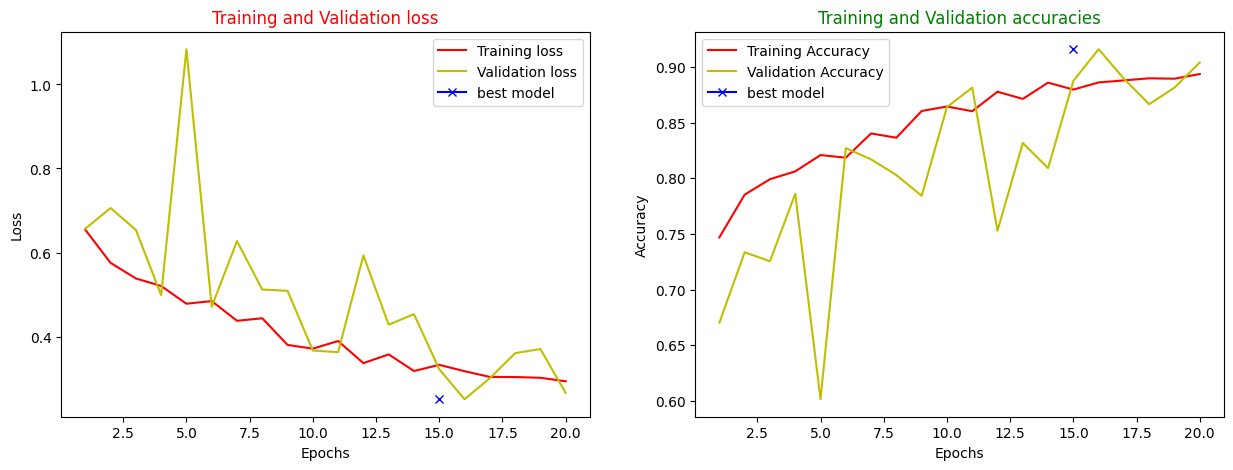

In [42]:
#training-validation loss curve
loss = history['loss']
val_loss = history['val_loss']
epochs = range(1, len(loss) + 1)

#training-validation accuracy curve
acc = history['accuracy']
val_acc = history['val_accuracy']

fig, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].plot(epochs, loss, 'r', label='Training loss')
axes[0].plot(epochs, val_loss, 'y', label='Validation loss')
axes[0].plot(np.argmin(history["val_loss"]), np.min(history["val_loss"]), marker="x", color="b", label="best model")
axes[0].set_title('Training and Validation loss',color="red")
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training loss.png',dpi=300)

axes[1].plot(epochs, acc, 'r', label='Training Accuracy')
axes[1].plot(epochs, val_acc, 'y', label='Validation Accuracy')
axes[1].plot(np.argmax(history["val_accuracy"]), np.max(history["val_accuracy"]), marker="x", color="b", label="best model")
axes[1].set_title('Training and Validation accuracies',color="green")
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training accuracies.png',dpi=300)

plt.show()

-------------------------------------------------------------------------------------------------

### *Now, to predict on our test data, we load the best model to predict and evaluate our model.*

In [32]:
model.load_weights("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Unet\\weights.19-0.42.hdf5")

In [33]:
preds_test_unet = model.predict(X_test, verbose=1)

1/1 [==============================] - 4s 4s/step


-------------------------------------------------------------------------------------------------

### *Since the output has passed the softmax function, we specify the highest value for each class using argmax so that decoding is performed on the predicted data.*

In [34]:
preds_test_argmax_unet = np.argmax(preds_test_unet, axis=3)
preds_test_argmax_unet_1=np.expand_dims(preds_test_argmax_unet, axis=-1)
pred_unet = preds_test_argmax_unet_1

In [35]:
p,k,l,z = pred_unet.shape
pred_unet_1 = pred_unet.reshape(p*k*l, z)
Y_test_1 = Y_test.reshape(p*k*l, z)

In [36]:
acc = accuracy_score(Y_test_1, pred_unet_1)
kappa = cohen_kappa_score(Y_test_1, pred_unet_1)
jaccard = jaccard_score(Y_test_1, pred_unet_1, average='macro')

In [37]:
table = pd.DataFrame({'Accuracy': [acc], 'Kappa': [kappa], 'Jaccard': [jaccard]})
table

,Accuracy,Kappa,Jaccard
0,0.701791,0.522152,0.475716


-------------------------------------------------------------------------------------------------

### *In the following, we glue together the predicted images in rows and columns to obtain the prediction of the entire region.*

In [38]:
pred_unet_2 = pred_unet[0:9,:,:,:]
Y_test_2 = Y_test[0:9,:,:,:]
X_test_2 = X_test[0:9,:,:,:]

result_pred = np.empty((0, 1536, 1))
result_label = np.empty((0, 1536, 1))
result_img = np.empty((0, 1536, 3))

for i in range(0, 9, 3):
    row = np.concatenate([pred_unet_2[i], pred_unet_2[i+1], pred_unet_2[i+2]], axis=1)
    row1 = np.concatenate([Y_test_2[i], Y_test_2[i+1], Y_test_2[i+2]], axis=1)
    row2 = np.concatenate([X_test_2[i], X_test_2[i+1], X_test_2[i+2]], axis=1)
    
    result_pred = np.concatenate([result_pred, row], axis=0)
    result_label = np.concatenate([result_label, row1], axis=0)
    result_img = np.concatenate([result_img, row2], axis=0)

In [39]:
def visualize(pred,label):
    
    f, axarr = plt.subplots(1,2,figsize = (20, 20), dpi=200)
    
    a=axarr[1]
    values = np.unique(label.ravel())
    plt.axis('off')

    colors = ['black' ,'white','green' ,'blue', 'red']
    cmap = ListedColormap(colors)
    legend_labels={'black' :'Background','white':'Building','green':'Woodland', 'blue': 'Water', 'red': 'Road'}

    patches = [Patch(color=color, label=label) for color, label in legend_labels.items()]
    plt.legend(handles=patches, bbox_to_anchor=(1.23,1.01), facecolor="wheat")

    axarr[0].set_axis_off()
    axarr[0].imshow(pred, cmap=cmap)
    axarr[0].set_title("Predicted Image", fontsize=18, y=1.01)
    
    im = axarr[1].imshow(label, cmap=cmap)
    axarr[1].set_title("Ground Truth Map", fontsize=18, y=1.01)

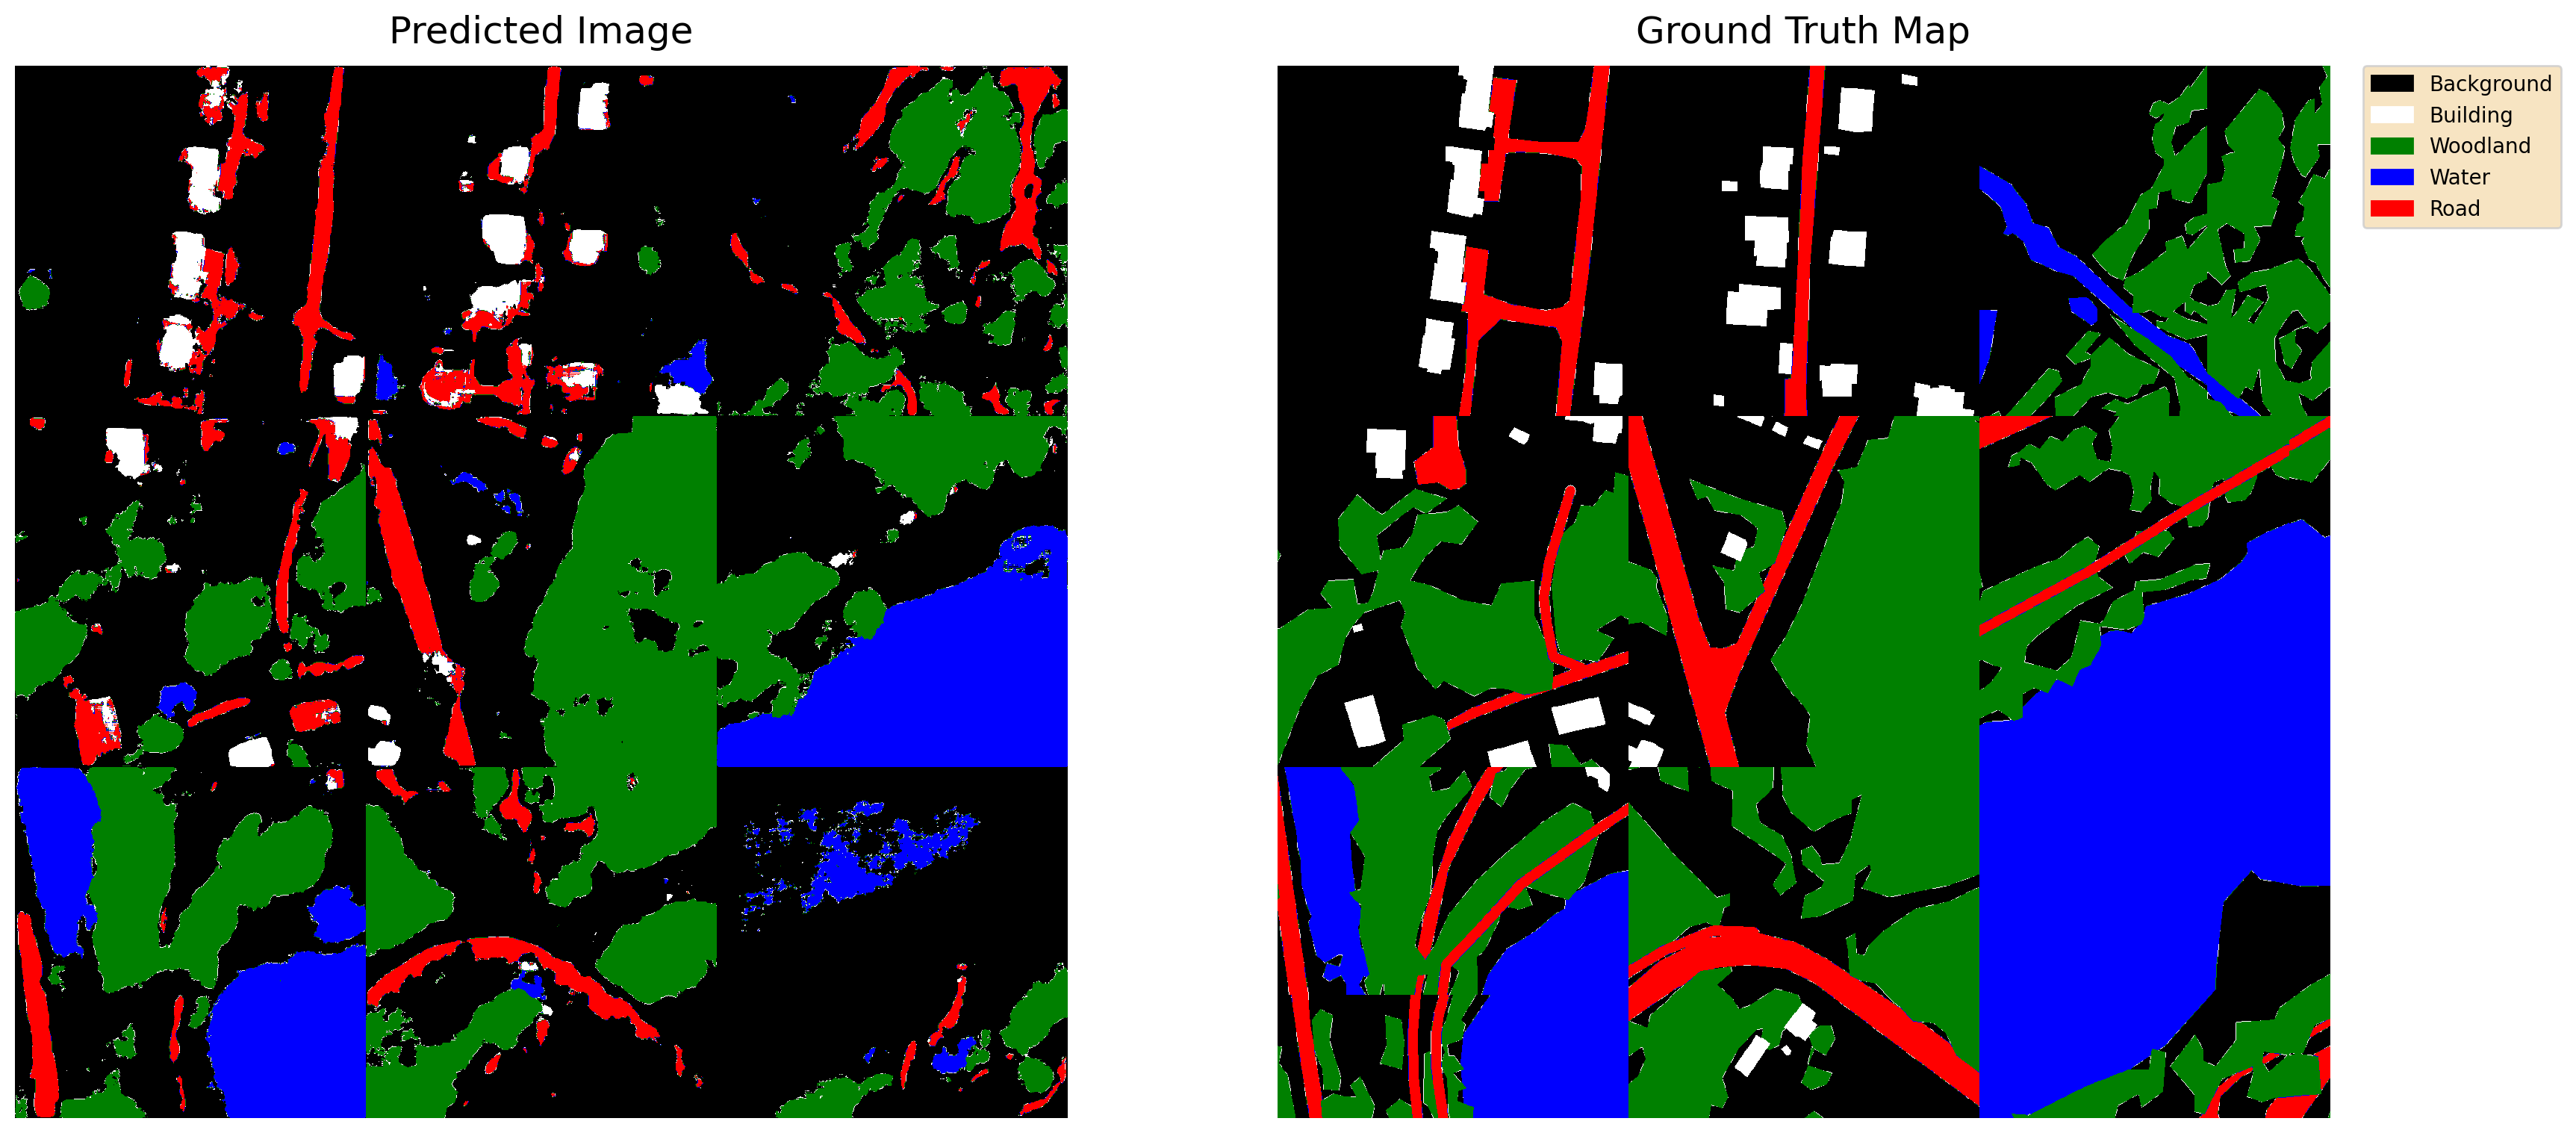

In [31]:
visualize(result_pred, result_label)

-------------------------------------------------------------------------------------------------

### *And at last, we show our final result*

In [52]:
def VisPredict_Truth(Img, GT, Pred) :
  p,k,l = Pred.shape
  Pred_r=Pred.reshape(p*k,l)
  GT_r=GT.reshape(p*k,l)


  plt.figure(figsize=(15,30))
    
  plt.subplot(131)
  plt.imshow((Img[:,:,:3] * -255).astype(np.uint8))
  plt.title("Original Image",fontsize=10, y=1.02)
  plt.axis('off')

  plt.subplot(132)
  colors = ['black' ,'white','green' ,'blue', 'red']
  cmap = ListedColormap(colors)
  legend_labels={'black' :'Background','white':'Building','green':'Woodland', 'blue': 'Water', 'red': 'Road'}
  patches = [Patch(color=color, label=label) for color, label in legend_labels.items()]
  plt.imshow(GT,cmap=cmap)
  plt.title("Ground Truth Image",fontsize=10, y=1.02)
  plt.axis('off')

  plt.subplot(133)
  patches = [Patch(color=color, label=label) for color, label in legend_labels.items()]
  plt.imshow(Pred,cmap=cmap)
  plt.title("Predicted Image ",fontsize=10, y=1.02)
  plt.axis('off')

  OA=sklearn.metrics.accuracy_score(GT_r,Pred_r)
  K_C=sklearn.metrics.cohen_kappa_score(GT_r,Pred_r)
  jaccard_score=sklearn.metrics.jaccard_score(GT_r,Pred_r,average='macro')

  t = PrettyTable(['Overall Accuracy','kappa coefficient','jaccard_score'])
  t.add_row(['% ' + str(round(OA*100,2)),
             '% ' + str(round(K_C*100,2)),
             '% ' + str(round(jaccard_score*100,2))])

  print(simple_colors.green(str(t),'bold'))

+------------------+-------------------+---------------+
| Overall Accuracy | kappa coefficient | jaccard_score |
+------------------+-------------------+---------------+
|     % 73.01      |      % 57.11      |    % 50.53    |
+------------------+-------------------+---------------+


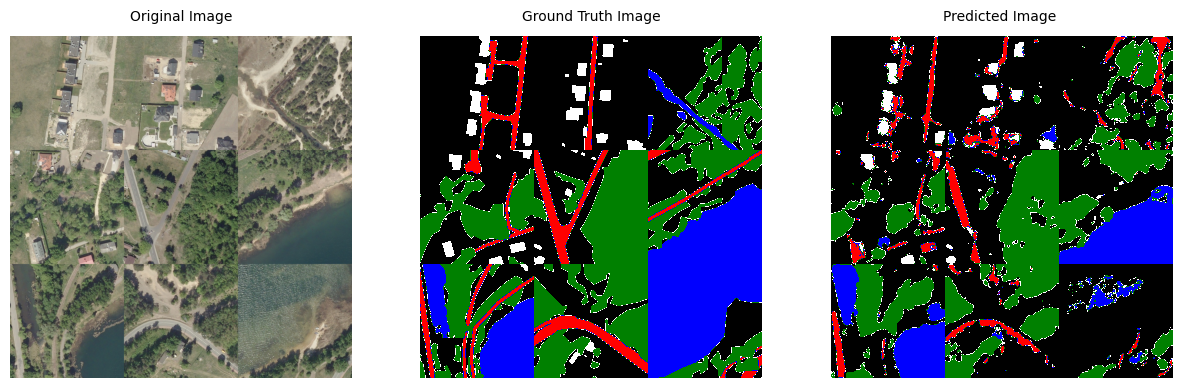

In [33]:
VisPredict_Truth(result_img, result_label, result_pred)

### *Now, after completing the steps for the Unet model, using the pretrained models and their obtained weights, we create 3 more models and repeat the same steps for them to finally check and compare the prediction results of these 4 models.*

In [12]:
sm.set_framework('tf.keras')
sm.framework()

'tf.keras'

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">3.1 Unet (Backbone : resnet34)</span>

In [35]:
# define model
base_model = sm.Unet(backbone_name='resnet34', encoder_weights='imagenet', classes=5, activation='softmax')

inp = Input(shape=(512, 512, 3))
l1 = Conv2D(5, (1, 1))(inp)
l1 = Conv2D(3, (1, 1))(l1)
out = base_model(l1)

model1 = Model(inp, out, name=base_model.name)

# compile keras model with defined optimozer, loss and metrics
model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics='accuracy')
model1.summary()

Model: "model_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_2 (InputLayer)         [(None, 512, 512, 3)]     0         
_________________________________________________________________
conv2d_19 (Conv2D)           (None, 512, 512, 5)       20        
_________________________________________________________________
conv2d_20 (Conv2D)           (None, 512, 512, 3)       18        
_________________________________________________________________
model_2 (Functional)         (None, None, None, 5)     24456734  
Total params: 24,456,772
Trainable params: 24,439,422
Non-trainable params: 17,350
_________________________________________________________________


-------------------------------------------------------------------------------------------------

In [36]:
# Checkpoint for saving the weights
checkpoint_path = os.path.join("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\ResNet34",'weights.{epoch:02d}-{loss:.2f}.hdf5')

# Create a callback that saves the model's weights at every epoch
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True, save_best_only=True, monitor="val_loss", mode = "min",
                                                 verbose=1)

# Create a callback to reduce the learning rate using the ReduceLROnPlateau function
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.33, patience=10, mode="min")

#Finding the optimal number of epochs to avoid overfitting
earlystopping = callbacks.EarlyStopping(monitor ="loss",
                                        mode ="min", patience=25,
                                        restore_best_weights=True)


# Compile the checkpoints and other settings as a callback
callback_list = [callback,reduce_lr, earlystopping]

In [38]:
start1 = datetime.now()
results1 = model1.fit(train_generator, steps_per_epoch = len(X_train)//4, epochs = 20, 
                    validation_data = val_generator, validation_steps = len(X_val)//4,
                    callbacks = callback_list)

stop1 = datetime.now()
execution_time = stop1-start1
print('U_net execution time is: ', execution_time)

Epoch 1/20
400/400 [==============================] - 269s 671ms/step - loss: 0.6542 - accuracy: 0.7468 - val_loss: 0.6568 - val_accuracy: 0.6702

Epoch 00001: val_loss improved from 1.12303 to 0.65678, saving model to D:\Learning\GeoAi\Week10\Projects\Models\ResNet34\weights.01-0.65.hdf5
Epoch 2/20
400/400 [==============================] - 267s 668ms/step - loss: 0.5754 - accuracy: 0.7852 - val_loss: 0.7059 - val_accuracy: 0.7335

Epoch 00002: val_loss did not improve from 0.65678
Epoch 3/20
400/400 [==============================] - 267s 668ms/step - loss: 0.5384 - accuracy: 0.7991 - val_loss: 0.6540 - val_accuracy: 0.7254

Epoch 00003: val_loss improved from 0.65678 to 0.65401, saving model to D:\Learning\GeoAi\Week10\Projects\Models\ResNet34\weights.03-0.54.hdf5
Epoch 4/20
400/400 [==============================] - 267s 668ms/step - loss: 0.5205 - accuracy: 0.8061 - val_loss: 0.4988 - val_accuracy: 0.7859

Epoch 00004: val_loss improved from 0.65401 to 0.49876, saving model to D:\

-------------------------------------------------------------------------------------------------

In [39]:
np.save('D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Resnet34_history.npy', results1.history)
history = np.load("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Resnet34_history.npy", allow_pickle='TRUE').item()

In [40]:
DF = pd.DataFrame(history)

# # save the dataframe as a csv file
DF.to_csv("Resnet34_history.csv")

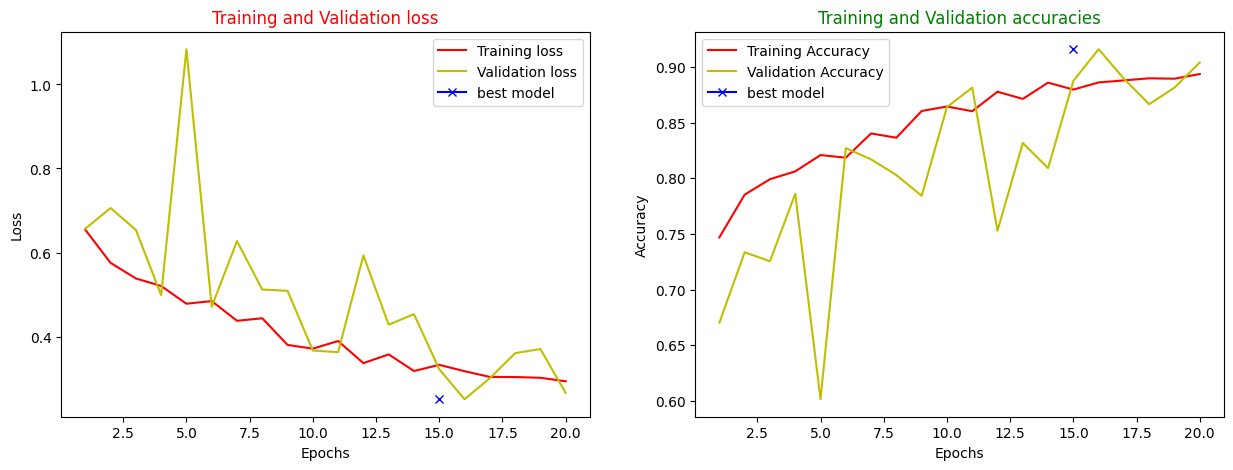

In [43]:
#training-validation loss curve
loss = history['loss']
val_loss = history['val_loss']
epochs = range(1, len(loss) + 1)

#training-validation accuracy curve
acc = history['accuracy']
val_acc = history['val_accuracy']

fig, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].plot(epochs, loss, 'r', label='Training loss')
axes[0].plot(epochs, val_loss, 'y', label='Validation loss')
axes[0].plot(np.argmin(history["val_loss"]), np.min(history["val_loss"]), marker="x", color="b", label="best model")
axes[0].set_title('Training and Validation loss',color="red")
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training loss.png',dpi=300)

axes[1].plot(epochs, acc, 'r', label='Training Accuracy')
axes[1].plot(epochs, val_acc, 'y', label='Validation Accuracy')
axes[1].plot(np.argmax(history["val_accuracy"]), np.max(history["val_accuracy"]), marker="x", color="b", label="best model")
axes[1].set_title('Training and Validation accuracies',color="green")
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training accuracies.png',dpi=300)

plt.show()

-------------------------------------------------------------------------------------------------

In [50]:
model1.load_weights("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\ResNet34\\weights.16-0.32.hdf5")

In [51]:
preds_test_resnet = model1.predict(X_test, verbose=1)

1/1 [==============================] - 0s 29ms/step


-------------------------------------------------------------------------------------------------

In [52]:
preds_test_argmax_resnet = np.argmax(preds_test_resnet, axis=3)
preds_test_argmax_resnet_1=np.expand_dims(preds_test_argmax_resnet, axis=-1)
pred_resnet = preds_test_argmax_resnet_1

In [53]:
p,k,l,z = pred_resnet.shape
pred_resnet_1 = pred_resnet.reshape(p*k*l, z)

In [54]:
acc = accuracy_score(Y_test_1, pred_resnet_1)
kappa = cohen_kappa_score(Y_test_1, pred_resnet_1)
jaccard = jaccard_score(Y_test_1, pred_resnet_1, average='macro')

In [55]:
table = pd.DataFrame({'Accuracy': [acc], 'Kappa': [kappa], 'Jaccard': [jaccard]})
table

,Accuracy,Kappa,Jaccard
0,0.733871,0.579942,0.500402


-------------------------------------------------------------------------------------------------

In [56]:
pred_resnet_2 = pred_resnet[0:9,:,:,:]
result_pred = np.empty((0, 1536, 1))

for i in range(0, 9, 3):
    row = np.concatenate([pred_resnet_2[i], pred_resnet_2[i+1], pred_resnet_2[i+2]], axis=1)
    result_pred = np.concatenate([result_pred, row], axis=0)

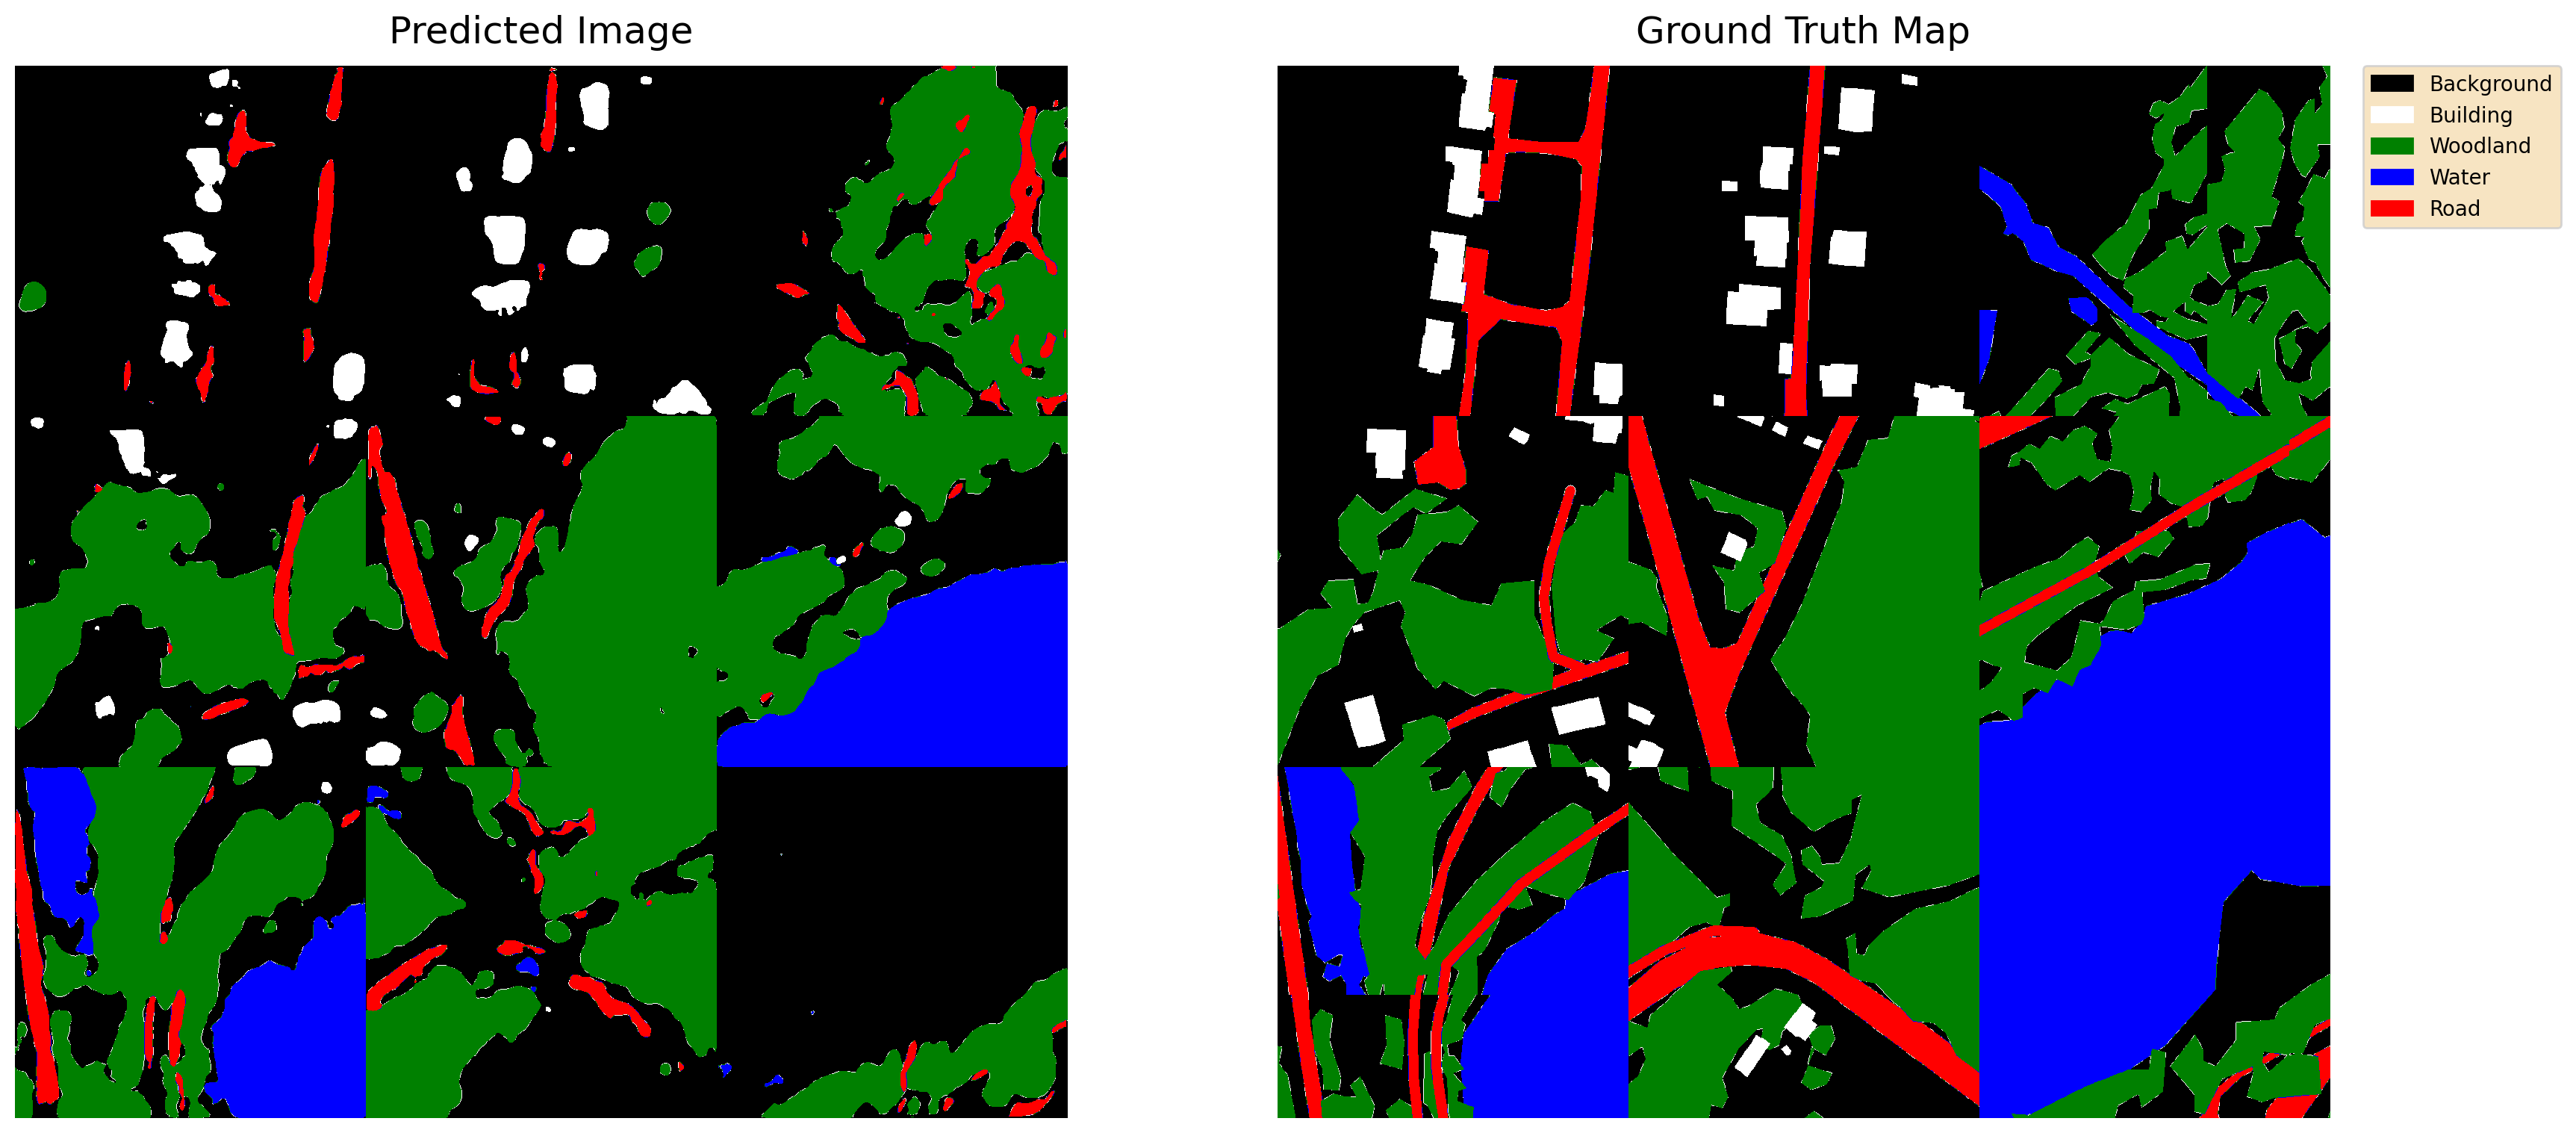

In [57]:
visualize(result_pred, result_label)

-------------------------------------------------------------------------------------------------

+------------------+-------------------+---------------+
| Overall Accuracy | kappa coefficient | jaccard_score |
+------------------+-------------------+---------------+
|     % 76.32      |      % 62.84      |     % 52.8    |
+------------------+-------------------+---------------+


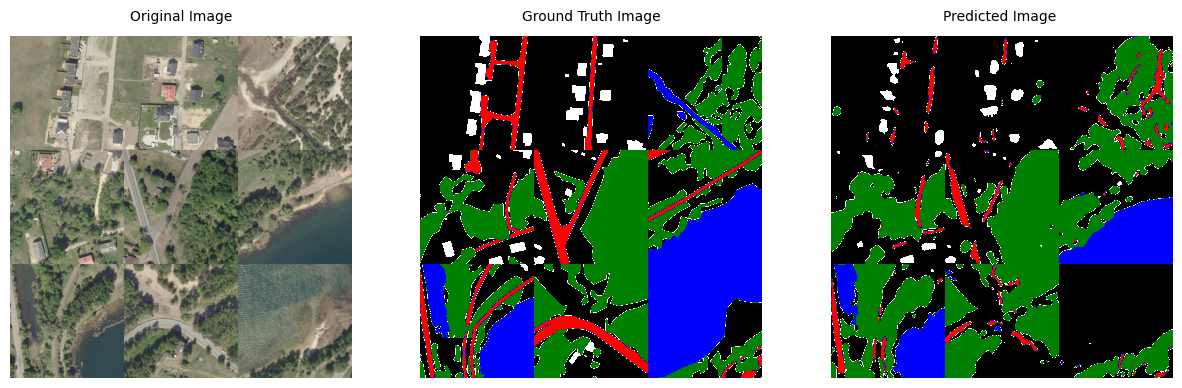

In [58]:
VisPredict_Truth(result_img, result_label, result_pred)

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">3.2 Unet (Backbone : vgg16)</span>

In [41]:
# define model
base_model = sm.Unet(backbone_name='vgg16', encoder_weights='imagenet', classes=5, activation='softmax')

inp = Input(shape=(512, 512, 3))
l1 = Conv2D(5, (1, 1))(inp)
l1 = Conv2D(3, (1, 1))(l1)
out = base_model(l1)

model2 = Model(inp, out, name=base_model.name)

# compile keras model with defined optimozer, loss and metrics
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics='accuracy')
model2.summary()

Model: "model_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_8 (InputLayer)         [(None, 512, 512, 3)]     0         
_________________________________________________________________
conv2d_211 (Conv2D)          (None, 512, 512, 5)       20        
_________________________________________________________________
conv2d_212 (Conv2D)          (None, 512, 512, 3)       18        
_________________________________________________________________
model_3 (Functional)         (None, None, None, 5)     23752853  
Total params: 23,752,891
Trainable params: 23,748,859
Non-trainable params: 4,032
_________________________________________________________________


-------------------------------------------------------------------------------------------------

In [42]:
# Checkpoint for saving the weights
checkpoint_path = os.path.join("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\VGG16",'weights.{epoch:02d}-{loss:.2f}.hdf5')

# Create a callback that saves the model's weights at every epoch
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True, save_best_only=True, monitor="val_loss", mode = "min",
                                                 verbose=1)

# Create a callback to reduce the learning rate using the ReduceLROnPlateau function
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.33, patience=10, mode="min")

#Finding the optimal number of epochs to avoid overfitting
earlystopping = callbacks.EarlyStopping(monitor ="loss",
                                        mode ="min", patience=25,
                                        restore_best_weights=True)


# Compile the checkpoints and other settings as a callback
callback_list = [callback,reduce_lr, earlystopping]

In [63]:
start1 = datetime.now()
results2 = model2.fit(train_generator, steps_per_epoch = len(X_train)//4, epochs = 20, 
                    validation_data = val_generator, validation_steps = len(X_val)//4,
                    callbacks = callback_list)

stop1 = datetime.now()
execution_time = stop1-start1
print('Vgg16 execution time is: ', execution_time)

Epoch 1/20
400/400 [==============================] - 667s 2s/step - loss: 0.7433 - accuracy: 0.6989 - val_loss: 1.4217 - val_accuracy: 0.5796

Epoch 00001: val_loss did not improve from 0.74576
Epoch 2/20
400/400 [==============================] - 673s 2s/step - loss: 0.6856 - accuracy: 0.7304 - val_loss: 0.8491 - val_accuracy: 0.6099

Epoch 00002: val_loss did not improve from 0.74576
Epoch 3/20
400/400 [==============================] - 673s 2s/step - loss: 0.6549 - accuracy: 0.7405 - val_loss: 0.5826 - val_accuracy: 0.7571

Epoch 00003: val_loss improved from 0.74576 to 0.58262, saving model to D:\Learning\GeoAi\Week10\Projects\Models\VGG16\weights.03-0.65.hdf5
Epoch 4/20
400/400 [==============================] - 650s 2s/step - loss: 0.6134 - accuracy: 0.7653 - val_loss: 0.5109 - val_accuracy: 0.8131

Epoch 00004: val_loss improved from 0.58262 to 0.51093, saving model to D:\Learning\GeoAi\Week10\Projects\Models\VGG16\weights.04-0.61.hdf5
Epoch 5/20
400/400 [======================

-------------------------------------------------------------------------------------------------

In [ ]:
np.save('D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\VGG16_history.npy', results2.history)
history = np.load("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\VGG16_history.npy", allow_pickle='TRUE').item()

In [65]:
DF = pd.DataFrame(history)

# # save the dataframe as a csv file
DF.to_csv("VGG16_history.csv")

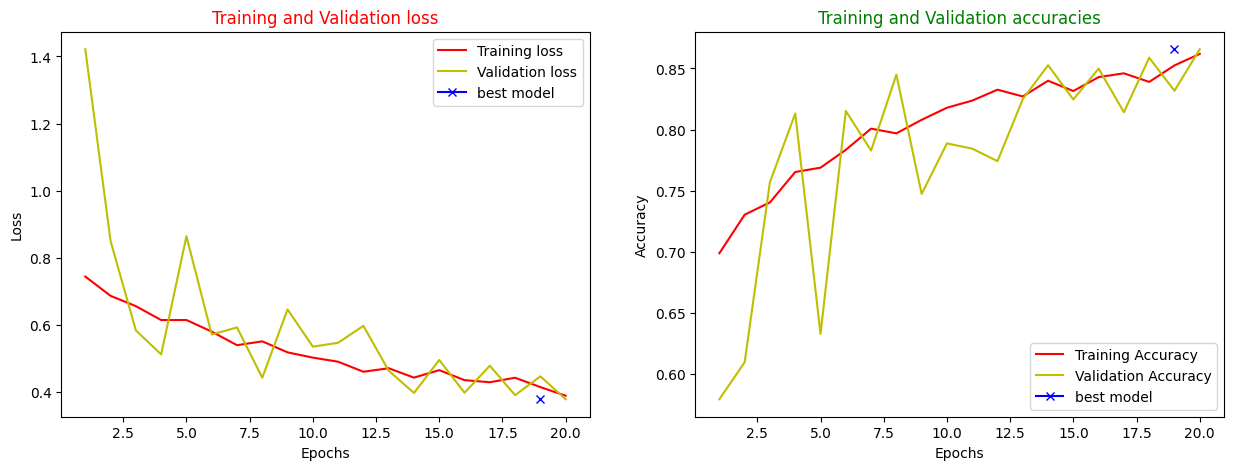

In [66]:
#training-validation loss curve
loss = history['loss']
val_loss = history['val_loss']
epochs = range(1, len(loss) + 1)

#training-validation accuracy curve
acc = history['accuracy']
val_acc = history['val_accuracy']

fig, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].plot(epochs, loss, 'r', label='Training loss')
axes[0].plot(epochs, val_loss, 'y', label='Validation loss')
axes[0].plot(np.argmin(history["val_loss"]), np.min(history["val_loss"]), marker="x", color="b", label="best model")
axes[0].set_title('Training and Validation loss',color="red")
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training loss.png',dpi=300)

axes[1].plot(epochs, acc, 'r', label='Training Accuracy')
axes[1].plot(epochs, val_acc, 'y', label='Validation Accuracy')
axes[1].plot(np.argmax(history["val_accuracy"]), np.max(history["val_accuracy"]), marker="x", color="b", label="best model")
axes[1].set_title('Training and Validation accuracies',color="green")
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training accuracies.png',dpi=300)

plt.show()

-------------------------------------------------------------------------------------------------

In [43]:
model2.load_weights("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\VGG16\\weights.20-0.39.hdf5")

In [44]:
preds_test_vgg16 = model2.predict(X_test, verbose=1)

1/1 [==============================] - 0s 216ms/step


-------------------------------------------------------------------------------------------------

In [45]:
preds_test_argmax_vgg16 = np.argmax(preds_test_vgg16, axis=3)
preds_test_argmax_vgg16_1=np.expand_dims(preds_test_argmax_vgg16, axis=-1)
pred_vgg16 = preds_test_argmax_vgg16_1

In [46]:
p,k,l,z = pred_vgg16.shape
pred_vgg16_1 = pred_vgg16.reshape(p*k*l, z)

In [47]:
acc = accuracy_score(Y_test_1, pred_vgg16_1)
kappa = cohen_kappa_score(Y_test_1, pred_vgg16_1)
jaccard = jaccard_score(Y_test_1, pred_vgg16_1, average='macro')

In [48]:
table = pd.DataFrame({'Accuracy': [acc], 'Kappa': [kappa], 'Jaccard': [jaccard]})
table

,Accuracy,Kappa,Jaccard
0,0.685158,0.489977,0.437389


-------------------------------------------------------------------------------------------------

In [49]:
pred_vgg16_2 = pred_vgg16[0:9,:,:,:]
result_pred = np.empty((0, 1536, 1))

for i in range(0, 9, 3):
    row = np.concatenate([pred_vgg16_2[i], pred_vgg16_2[i+1], pred_vgg16_2[i+2]], axis=1)
    result_pred = np.concatenate([result_pred, row], axis=0)

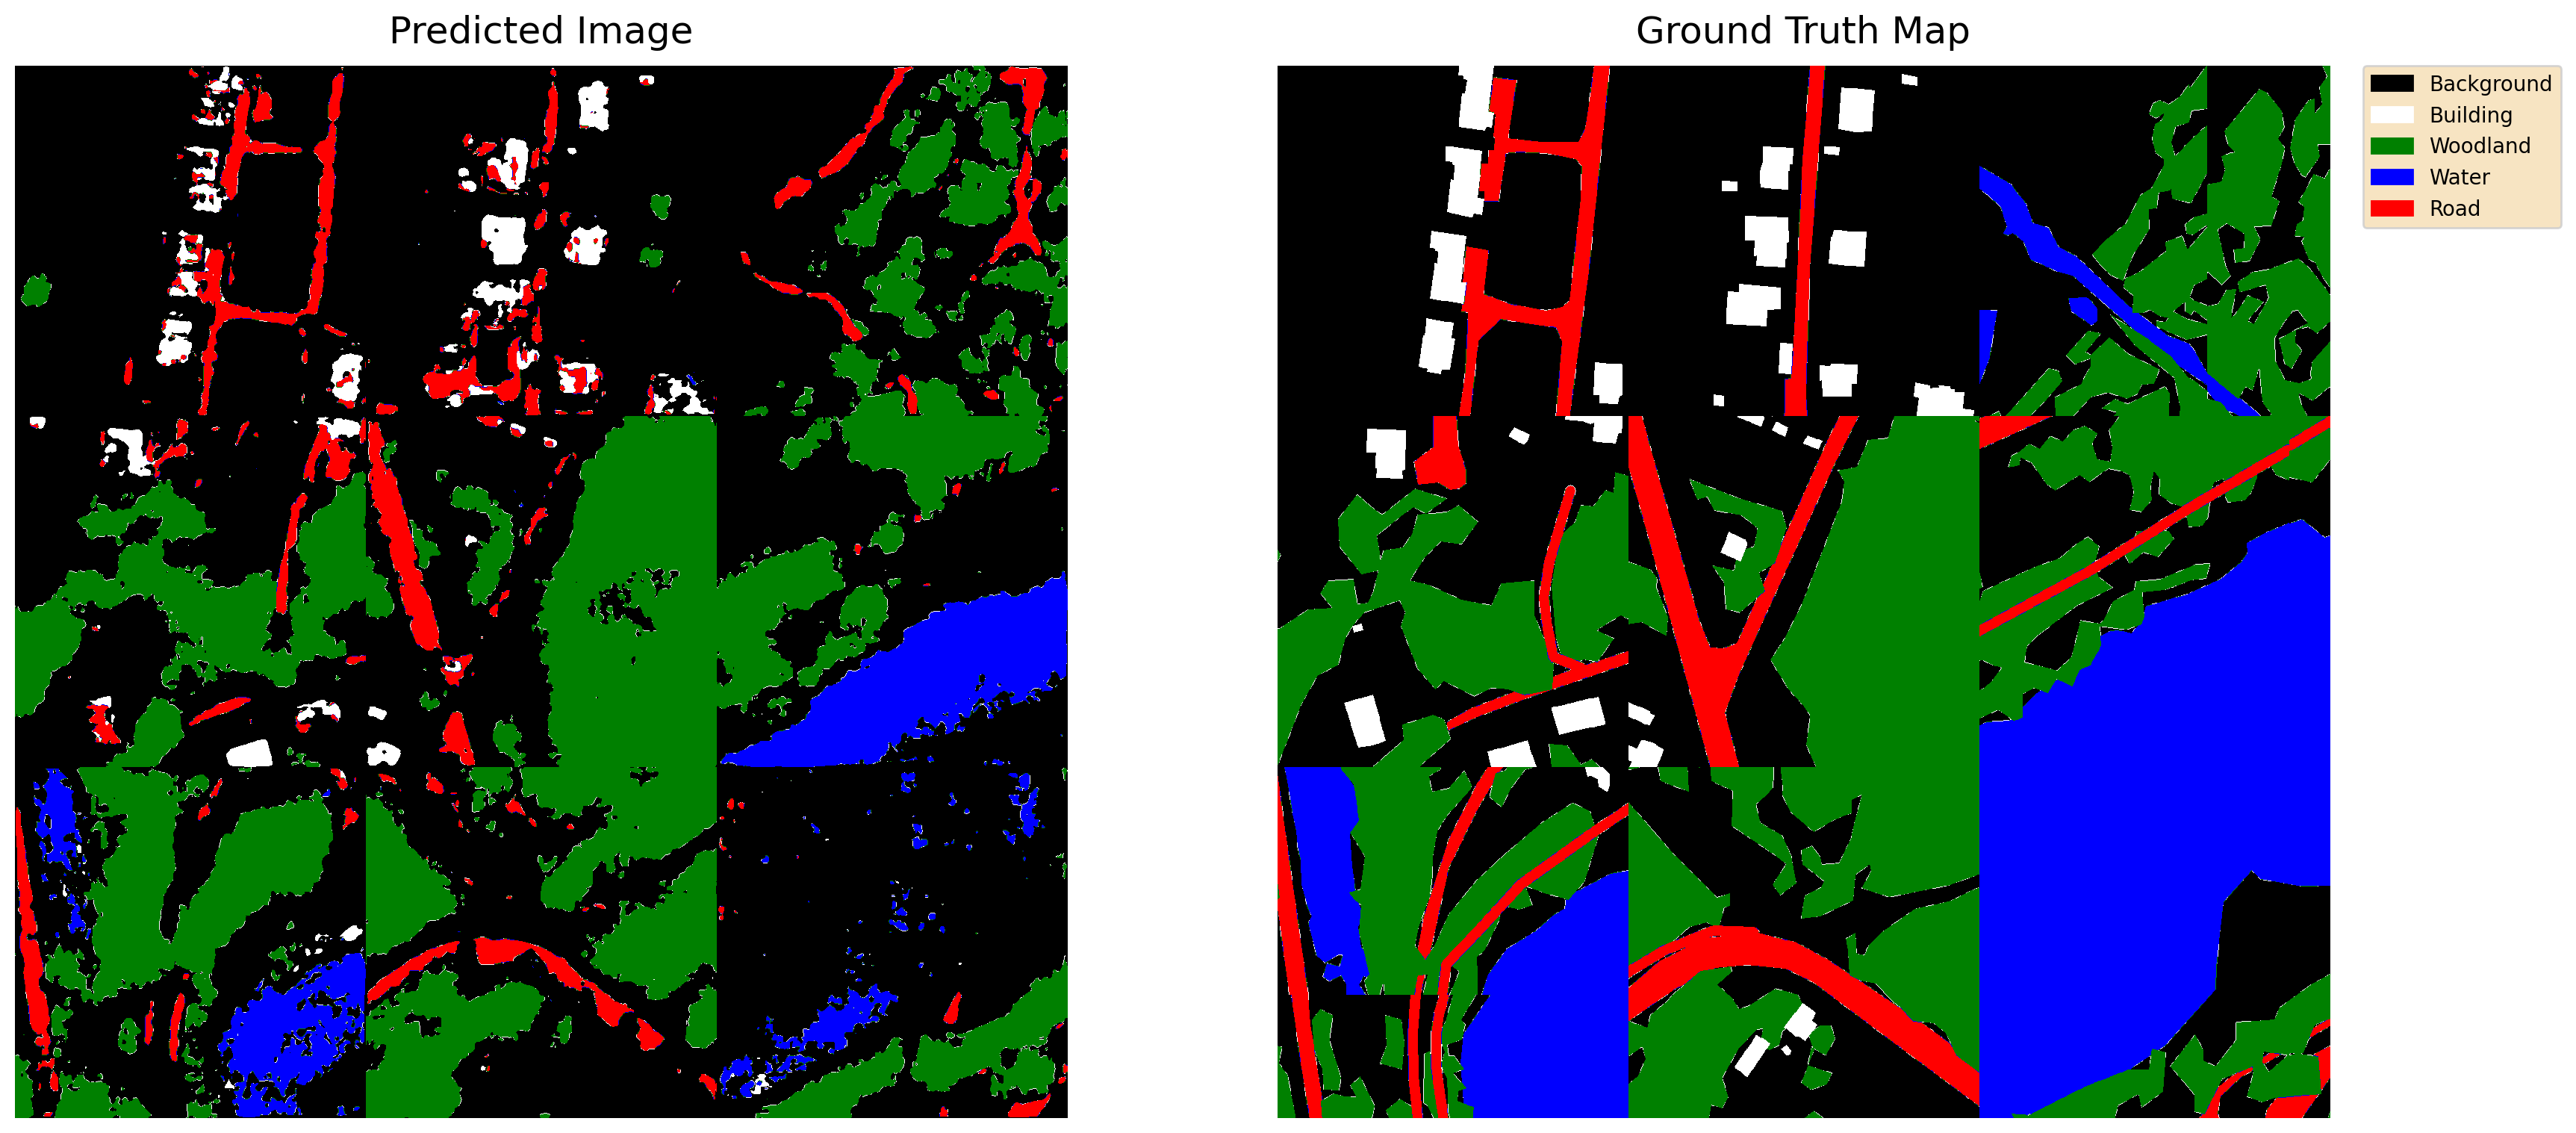

In [50]:
visualize(result_pred, result_label)

-------------------------------------------------------------------------------------------------

+------------------+-------------------+---------------+
| Overall Accuracy | kappa coefficient | jaccard_score |
+------------------+-------------------+---------------+
|     % 71.04      |      % 53.16      |    % 45.81    |
+------------------+-------------------+---------------+


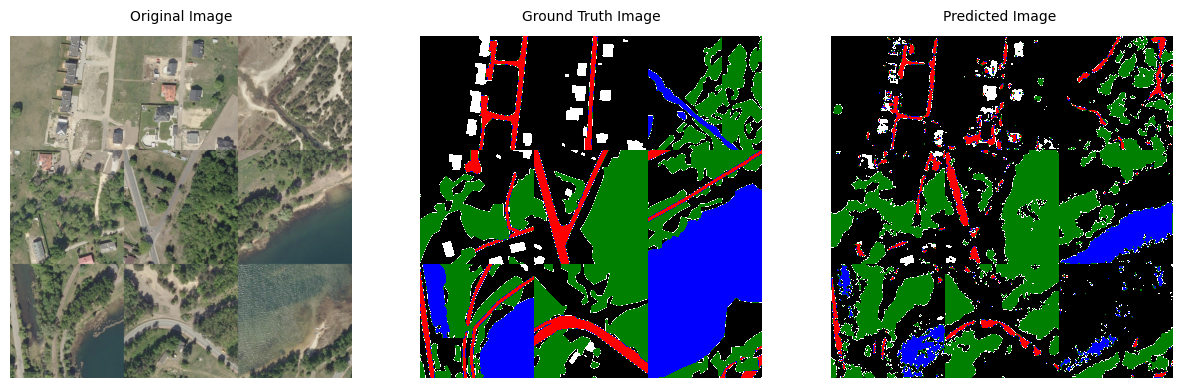

In [53]:
VisPredict_Truth(result_img, result_label, result_pred)

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">3.3 Unet (Backbone : inception)</span>

In [54]:
# define model
base_model = sm.Unet(backbone_name='inceptionv3', encoder_weights='imagenet', classes=5, activation='softmax')

inp = Input(shape=(512, 512, 3))
l1 = Conv2D(5, (1, 1))(inp)
l1 = Conv2D(3, (1, 1))(l1)
out = base_model(l1)

model3 = Model(inp, out, name=base_model.name)

# compile keras model with defined optimozer, loss and metrics
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics='accuracy')
model3.summary()

Model: "model_4"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_10 (InputLayer)        [(None, 512, 512, 3)]     0         
_________________________________________________________________
conv2d_307 (Conv2D)          (None, 512, 512, 5)       20        
_________________________________________________________________
conv2d_308 (Conv2D)          (None, 512, 512, 3)       18        
_________________________________________________________________
model_4 (Functional)         (None, None, None, 5)     29933685  
Total params: 29,933,723
Trainable params: 29,897,307
Non-trainable params: 36,416
_________________________________________________________________


-------------------------------------------------------------------------------------------------

In [55]:
# Checkpoint for saving the weights
checkpoint_path = os.path.join("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Inception",'weights.{epoch:02d}-{loss:.2f}.hdf5')

# Create a callback that saves the model's weights at every epoch
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True, save_best_only=True, monitor="val_loss", mode = "min",
                                                 verbose=1)

# Create a callback to reduce the learning rate using the ReduceLROnPlateau function
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.33, patience=10, mode="min")

#Finding the optimal number of epochs to avoid overfitting
earlystopping = callbacks.EarlyStopping(monitor ="loss",
                                        mode ="min", patience=25,
                                        restore_best_weights=True)


# Compile the checkpoints and other settings as a callback
callback_list = [callback,reduce_lr, earlystopping]

In [15]:
start1 = datetime.now()
results3 = model3.fit(train_generator, steps_per_epoch = len(X_train)//4, epochs = 20, 
                    validation_data = val_generator, validation_steps = len(X_val)//4,
                    callbacks = callback_list)

stop1 = datetime.now()
execution_time = stop1-start1
print('InceptionV3 execution time is: ', execution_time)

Epoch 1/20
400/400 [==============================] - 208s 455ms/step - loss: 0.8927 - accuracy: 0.6527 - val_loss: 31.9748 - val_accuracy: 0.6711

Epoch 00001: val_loss improved from inf to 31.97477, saving model to D:\Learning\GeoAi\Week10\Projects\Models\Inception\weights.01-0.89.hdf5
Epoch 2/20
400/400 [==============================] - 181s 452ms/step - loss: 0.7959 - accuracy: 0.6862 - val_loss: 2.0770 - val_accuracy: 0.6397

Epoch 00002: val_loss improved from 31.97477 to 2.07704, saving model to D:\Learning\GeoAi\Week10\Projects\Models\Inception\weights.02-0.80.hdf5
Epoch 3/20
400/400 [==============================] - 181s 452ms/step - loss: 0.7223 - accuracy: 0.7195 - val_loss: 0.7469 - val_accuracy: 0.7871

Epoch 00003: val_loss improved from 2.07704 to 0.74685, saving model to D:\Learning\GeoAi\Week10\Projects\Models\Inception\weights.03-0.72.hdf5
Epoch 4/20
400/400 [==============================] - 205s 513ms/step - loss: 0.6575 - accuracy: 0.7551 - val_loss: 1.8925 - val

-------------------------------------------------------------------------------------------------

In [57]:
np.save('D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\inception_history.npy', results3.history)
history = np.load("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\inception_history.npy", allow_pickle='TRUE').item()

In [58]:
DF = pd.DataFrame(history)

# save the dataframe as a csv file
DF.to_csv("inception_history.csv")

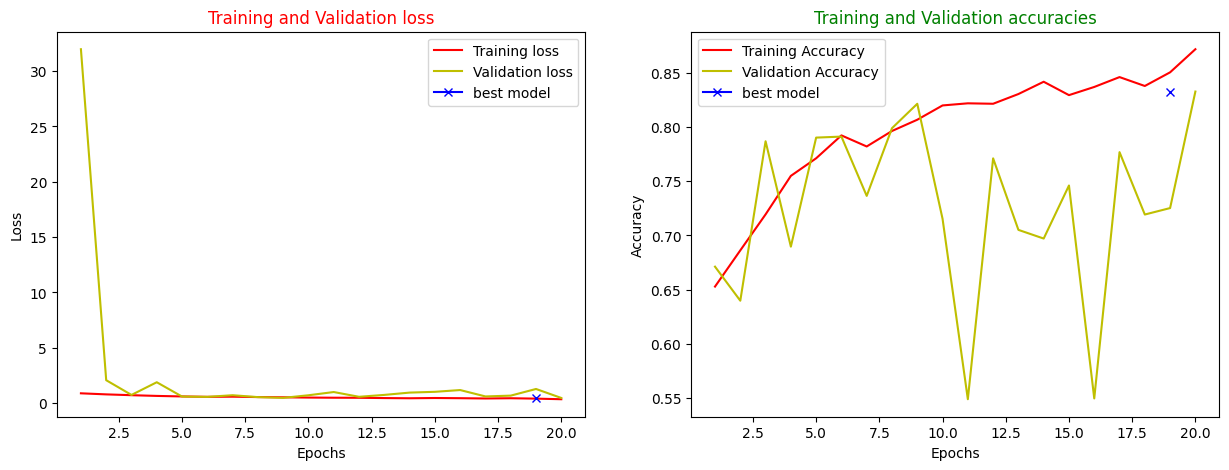

In [60]:
#training-validation loss curve
loss = history['loss']
val_loss = history['val_loss']
epochs = range(1, len(loss) + 1)

#training-validation accuracy curve
acc = history['accuracy']
val_acc = history['val_accuracy']

fig, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].plot(epochs, loss, 'r', label='Training loss')
axes[0].plot(epochs, val_loss, 'y', label='Validation loss')
axes[0].plot(np.argmin(history["val_loss"]), np.min(history["val_loss"]), marker="x", color="b", label="best model")
axes[0].set_title('Training and Validation loss',color="red")
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training loss.png',dpi=300)

axes[1].plot(epochs, acc, 'r', label='Training Accuracy')
axes[1].plot(epochs, val_acc, 'y', label='Validation Accuracy')
axes[1].plot(np.argmax(history["val_accuracy"]), np.max(history["val_accuracy"]), marker="x", color="b", label="best model")
axes[1].set_title('Training and Validation accuracies',color="green")
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
# plt.savefig('/content/drive/MyDrive/DARU_Net_Training accuracies.png',dpi=300)

plt.show()

-------------------------------------------------------------------------------------------------

In [61]:
model3.load_weights("D:\\Learning\\GeoAi\\Week10\\Projects\\Models\\Inception\\weights.20-0.36.hdf5")

In [62]:
preds_test_inception = model3.predict(X_test, verbose=1)

1/1 [==============================] - 10s 10s/step


-------------------------------------------------------------------------------------------------

In [65]:
preds_test_argmax_inception = np.argmax(preds_test_inception, axis=3)
preds_test_argmax_inception_1=np.expand_dims(preds_test_argmax_inception, axis=-1)
pred_inception = preds_test_argmax_inception_1

In [66]:
p,k,l,z = pred_inception.shape
pred_inception_1 = pred_inception.reshape(p*k*l, z)

In [67]:
acc = accuracy_score(Y_test_1, pred_inception_1)
kappa = cohen_kappa_score(Y_test_1, pred_inception_1)
jaccard = jaccard_score(Y_test_1, pred_inception_1, average='macro')

In [68]:
table = pd.DataFrame({'Accuracy': [acc], 'Kappa': [kappa], 'Jaccard': [jaccard]})
table

,Accuracy,Kappa,Jaccard
0,0.665956,0.469044,0.366987


-------------------------------------------------------------------------------------------------

In [69]:
pred_inception_2 = pred_inception[0:9,:,:,:]
result_pred = np.empty((0, 1536, 1))

for i in range(0, 9, 3):
    row = np.concatenate([pred_inception_2[i], pred_inception_2[i+1], pred_inception_2[i+2]], axis=1)
    result_pred = np.concatenate([result_pred, row], axis=0)

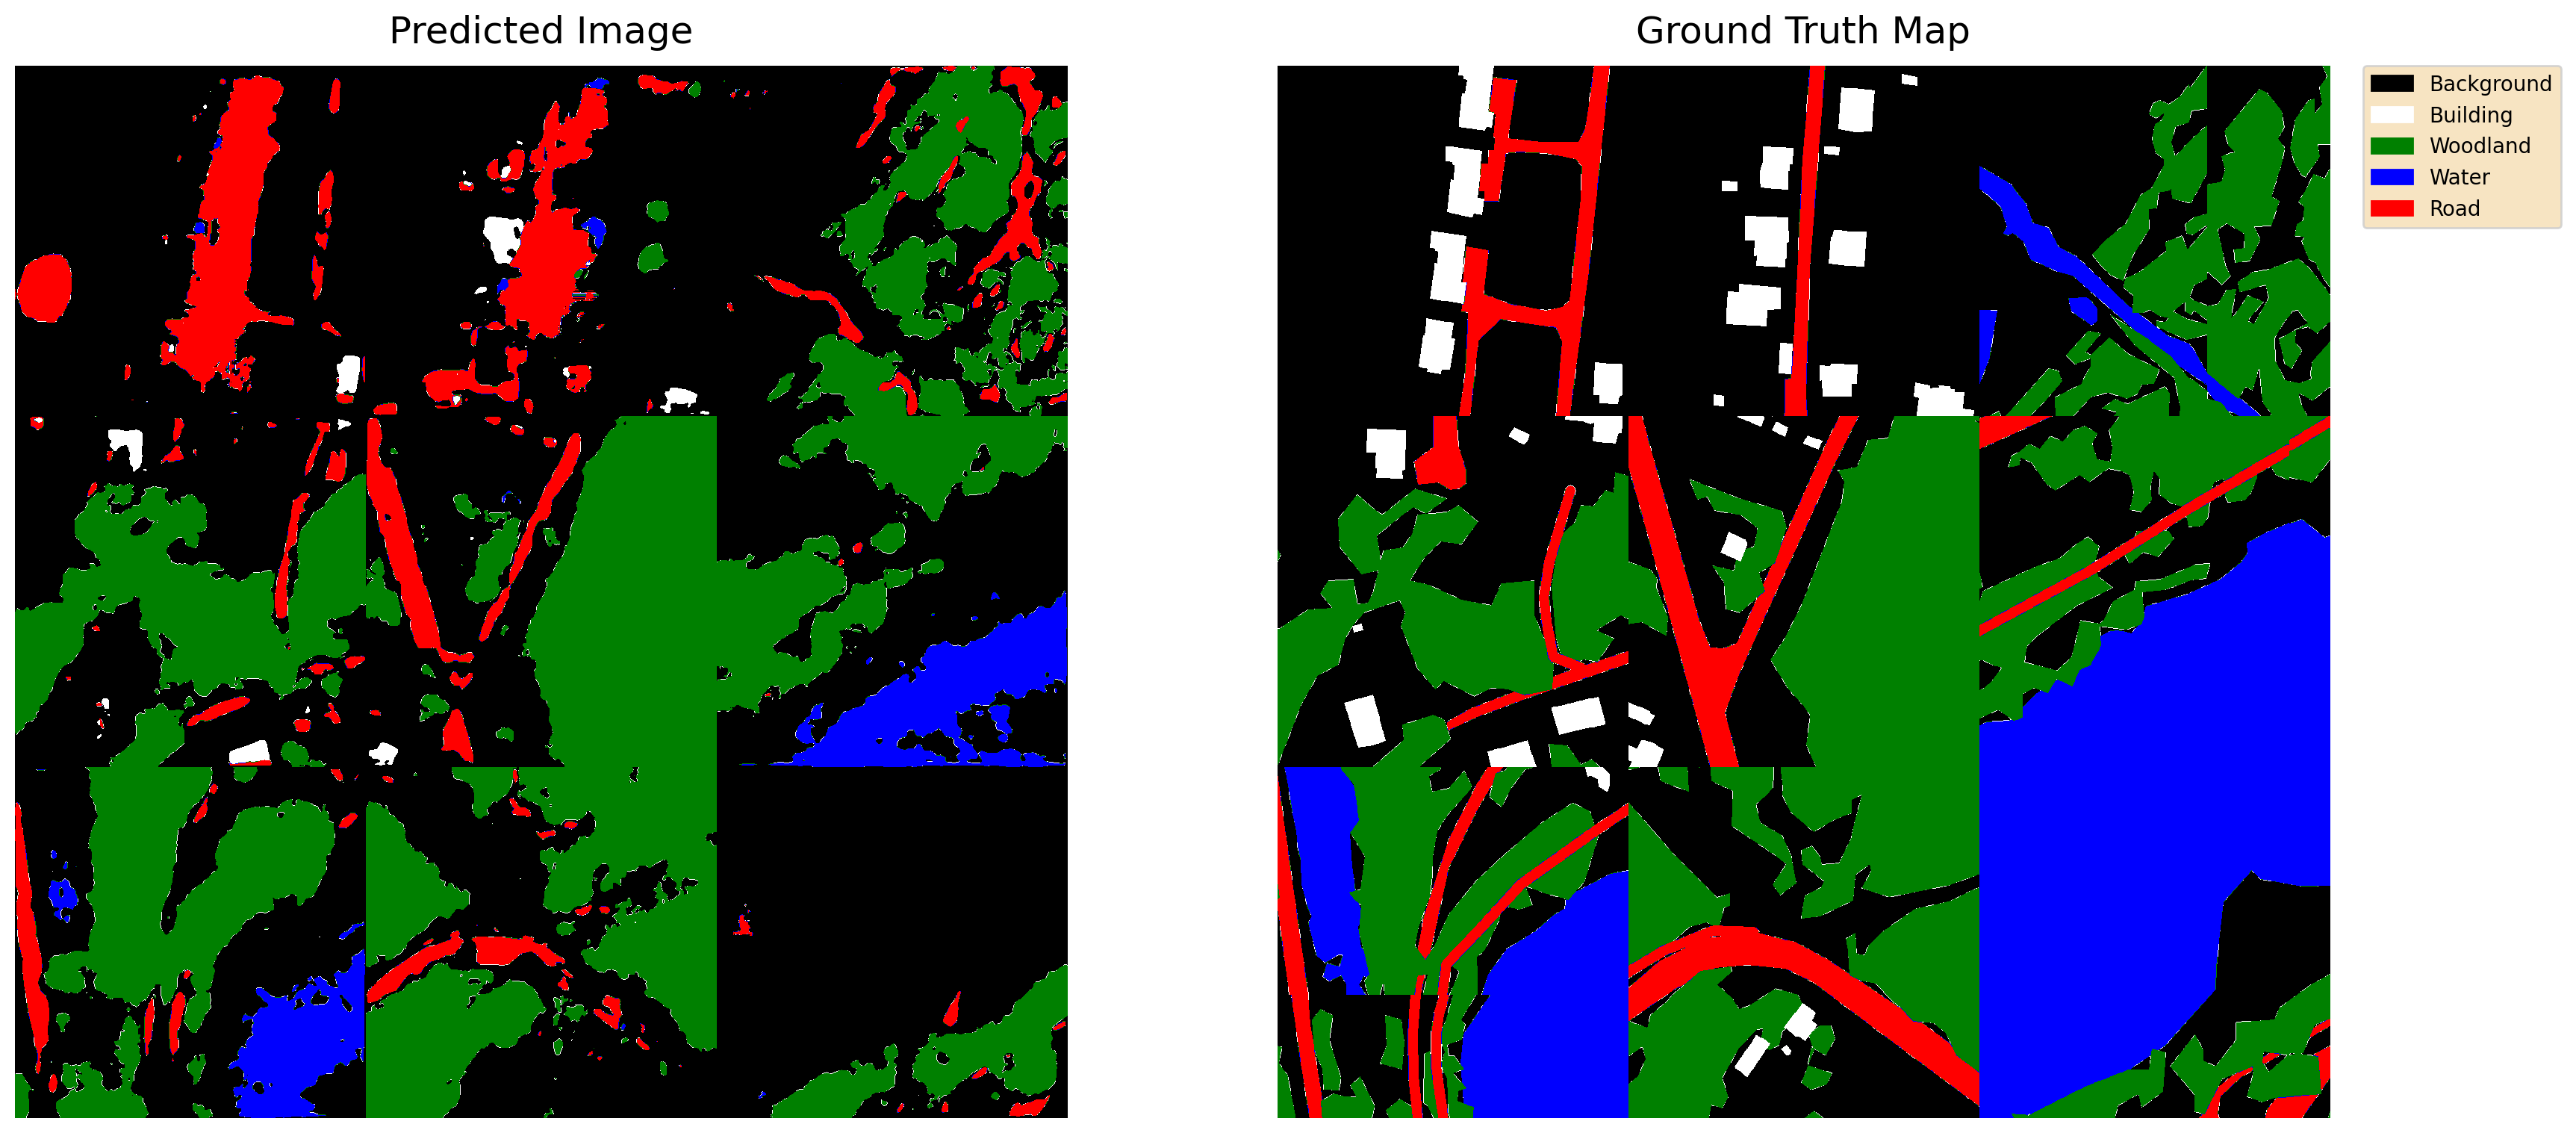

In [70]:
visualize(result_pred, result_label)

-------------------------------------------------------------------------------------------------

+------------------+-------------------+---------------+
| Overall Accuracy | kappa coefficient | jaccard_score |
+------------------+-------------------+---------------+
|     % 69.45      |      % 51.18      |    % 38.73    |
+------------------+-------------------+---------------+


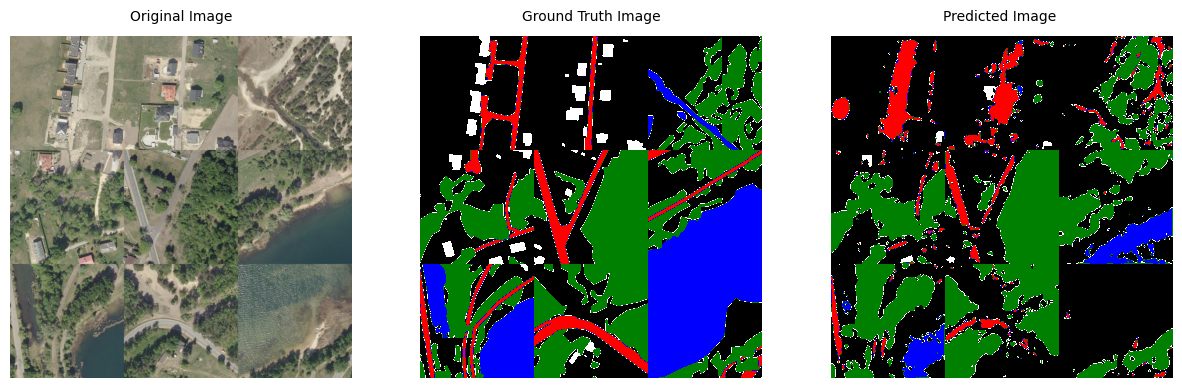

In [71]:
VisPredict_Truth(result_img, result_label, result_pred)

-------------------------------------------------------------------------------------------------

## <span style="color:yellow;">4. Conclusion</span>

### *In the final part, we will compare the outputs and examine the reasons for the difference in the accuracy of the models.*

### *For comparison, we display the accuracy and loss csv files of all 4 models in a chart using Excel.*

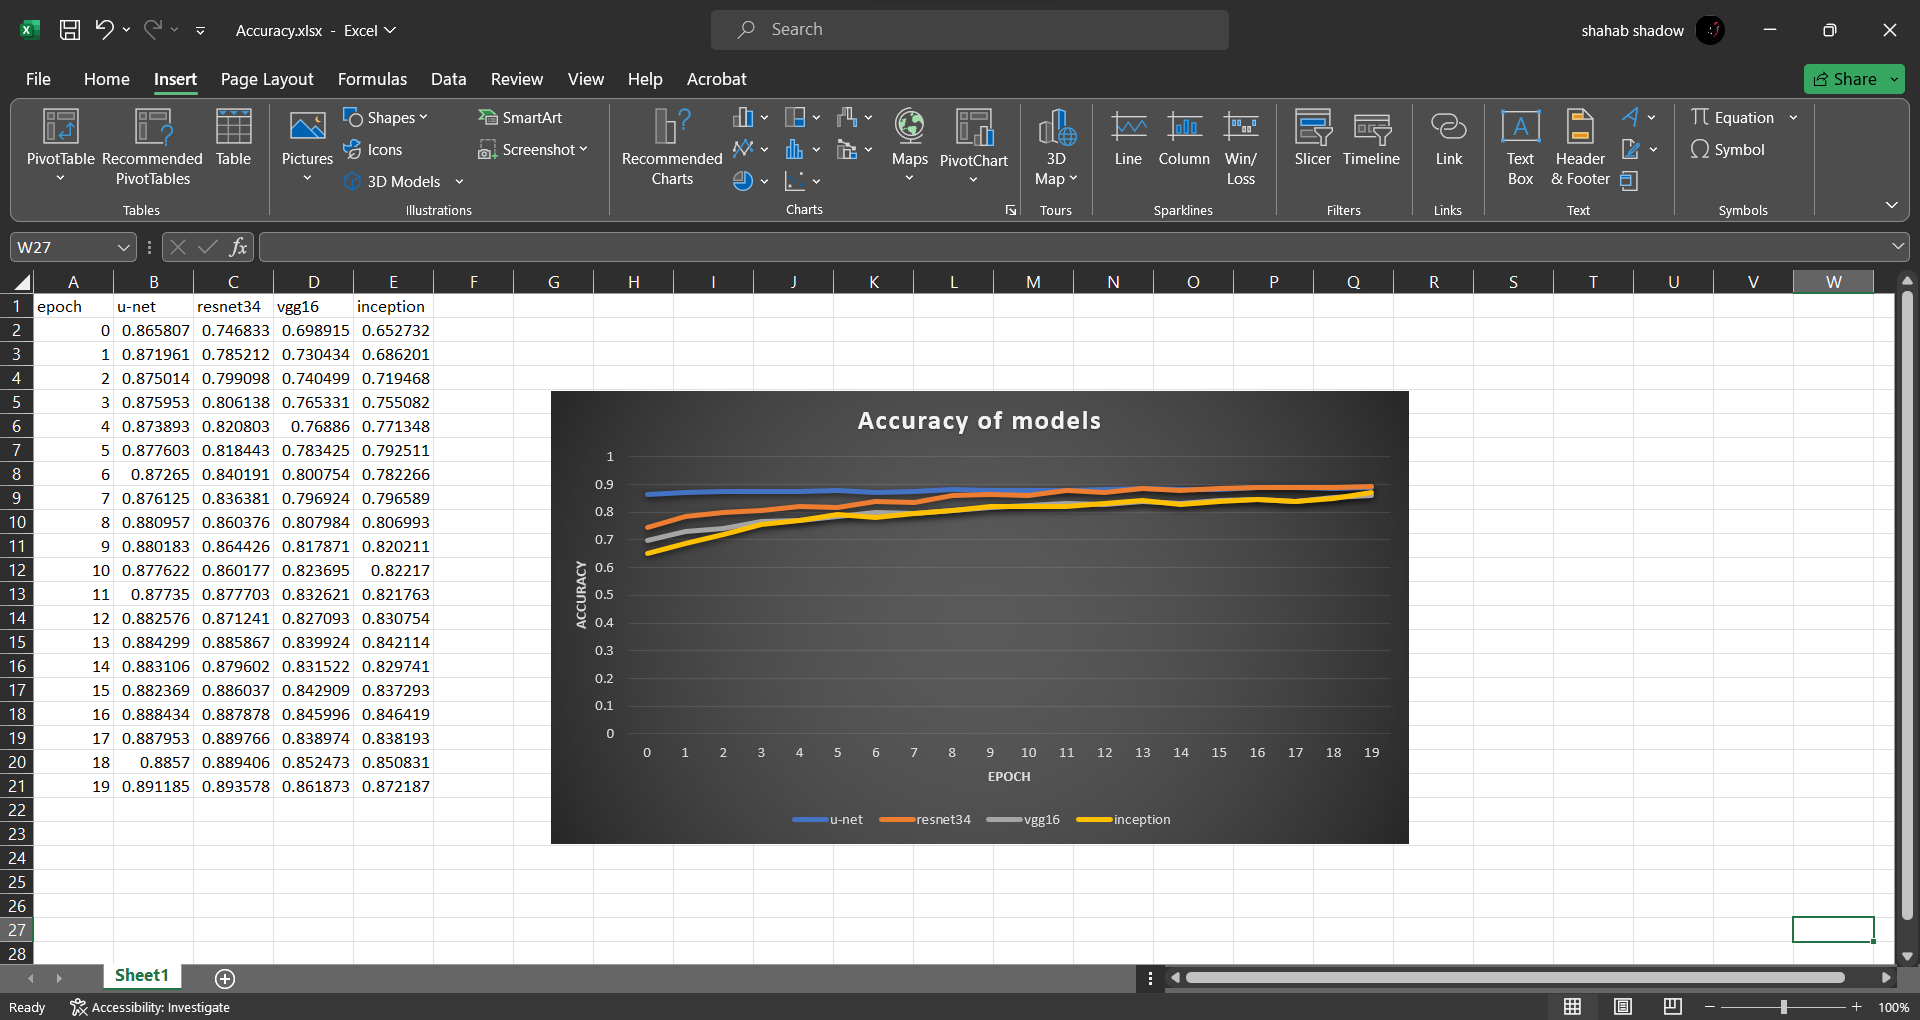

In [11]:
from IPython.display import Image
Image("D:\Learning\GeoAi\Week10\Projects/acc.png")

-------------------------------------------------------------------------------------------------

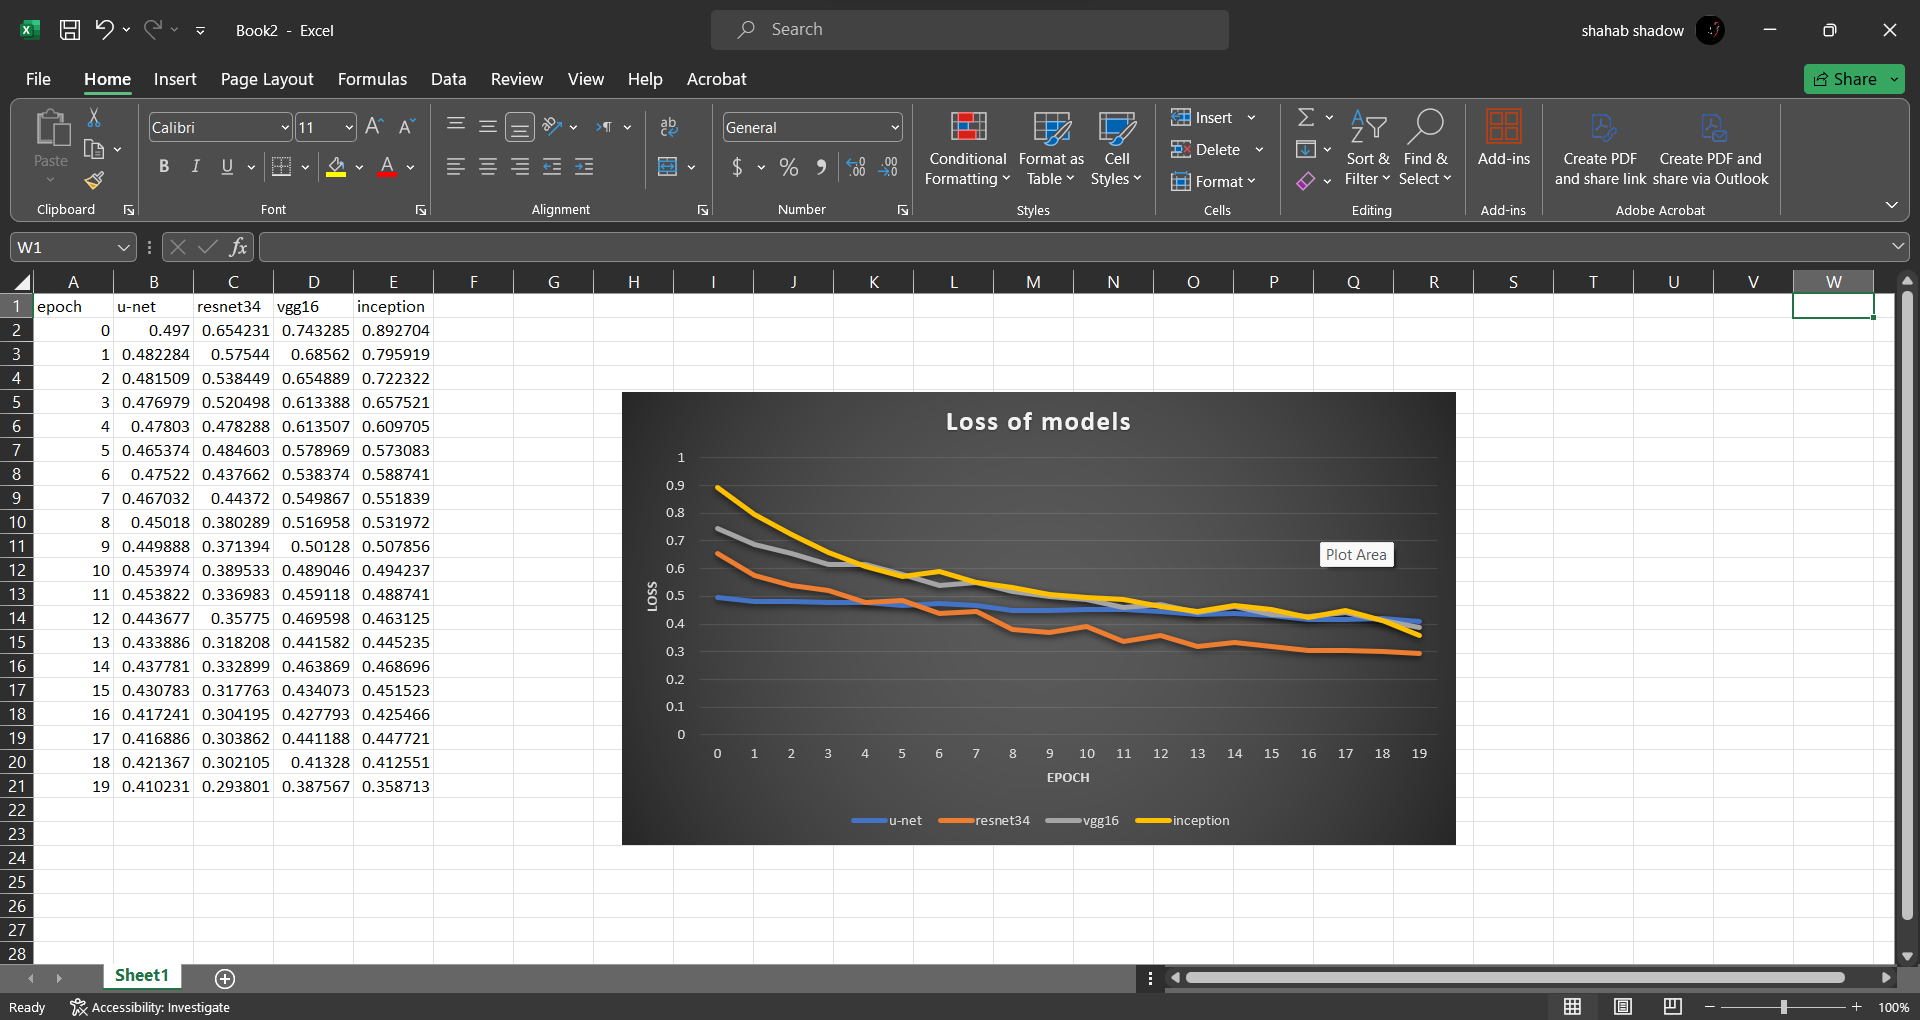

In [12]:
Image("D:\Learning\GeoAi\Week10\Projects/loss.png")

-------------------------------------------------------------------------------------------------

### *And finally, we put the value of the metrices calculated for the test data in a table for final comparison.*

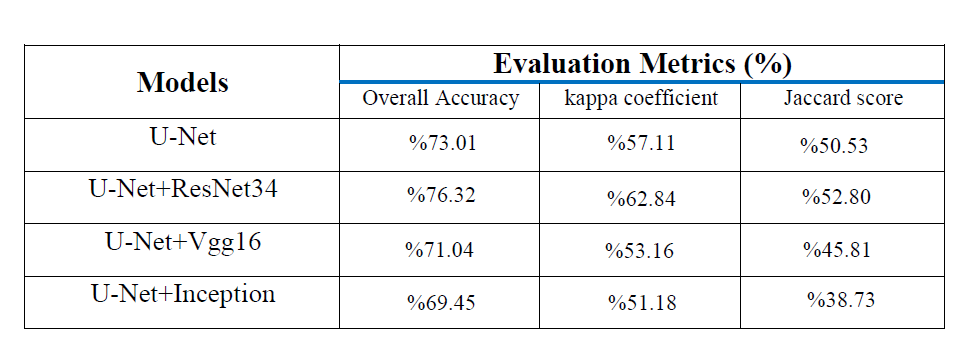

In [13]:
Image("D:\Learning\GeoAi\Week10\Projects/Screenshot 2023-11-12 215249.png")

-------------------------------------------------------------------------------------------------

### *At first, we need to give a brief introduction of each of these models :*

>*U-net : A convolutional neural network that is designed for image segmentation applications. This network has two parts: encoder and decoder, which are responsible for reducing and increasing the dimensions of the input image, respectively. The encoder part can use any other convolutional network as a base. The decoder part also uses convolutional layers and skip connections between the corresponding layers of the encoder and decoder to produce the output image with more details.*


>*Resnet34 : A deep convolutional network that is designed for image classification applications. This network consists of 34 convolutional layers that are organized as residual blocks. Each residual block contains two or three convolutional layers that use skip connections between the input and output of the block to solve the vanishing gradient problem. This network can classify images into 1000 different classes from the ImageNet dataset.*


>*Vgg16 : Another deep convolutional network that is designed for image classification applications. This network consists of 16 convolutional and fully connected layers that are organized as simple modules. Each module consists of several convolutional layers with a kernel size of 3x3 and a pooling layer. This network can also classify images into 1000 different classes from the ImageNet dataset.*


>*inception : A family of deep convolutional networks that are designed for image classification and object detection applications. These networks use more complex modules called inception modules that each consist of several convolutional and pooling layers with different kernel sizes. These modules allow the network to use different shallow and deep representations of the image. The third version of these networks, called inception v3, can also classify images into 1000 different classes from the ImageNet dataset.*


### *Now that we are familiar with the basic concepts of these models, we need to pay attention to several factors :*


>*The number of parameters of the model: Models that have more parameters are usually able to learn more complex features from the images. But these models need more training data to prevent overfitting. Based on the information in summary models, the number of parameters of the resnet34, vgg16 and inception v3 models are respectively 21.8 million, 138 million and 23.8 million. Therefore, we can say that the vgg16 model has much more parameters than the other two models and probably needs more training data. The resnet34 and inception v3 models also have similar numbers of parameters.*


>*The architecture of the model: Models that have a more optimal architecture are usually able to use their parameters better. The resnet and inception models use residual and inception modules that help the network to avoid problems such as vanishing gradient and increasing computational complexity. The vgg16 model uses simpler modules that may lead to reduced efficiency of the network.*


>*The compatibility of the model with the task: Models that have been trained for a similar task with the desired task are usually able to perform that task better. The resnet34, vgg16 and inception v3 models have been trained for the image classification task that can be related to the image segmentation task. But some of the features that these models have learned may not be suitable for the land cover classification prediction task. For example, the vgg16 model may pay more attention to the color and texture of the images that are useful for detecting different objects, but may not be enough for detecting the type of land cover. The resnet34 model may pay more attention to the shape and geometry of the images that are more useful for detecting the type of land cover.*


### *Considering these factors, we can say that the resnet34 model has performed better than the others because :*

>*- It has a suitable number of parameters that are not too many or too few.*

>*- It has an optimal architecture that uses residual modules.*

>*- It has a high compatibility with the land cover classification prediction task because it pays more attention to the shape and geometry of the images.*